# Data Structures & Algorithms: 🏭 Industry Project — DSA Inside Real AI Systems

> **Who is this for:** someone who has learned the classic data structures (heaps, hash maps, tries, graphs, dynamic programming, binary search) and wonders *"where would an AI engineer actually use these?"* Also useful for system-design and ML-engineering interviews.
>
> **What you will learn:** eight production-style case studies, each following the same pattern: **realistic scenario → naive approach → better data structure → measured speed/memory gain → production notes**.
>
> 1. **Heaps** for top-k retrieval (RAG, recommendations) over 1,000,000 scores
> 2. **Tries** for autocomplete and greedy longest-match tokenisation; a **tiny BPE tokenizer trainer** built on **hash maps + a priority queue**
> 3. **Hashing** for training-data deduplication (exact hashes, **MinHash + LSH**) and a **Bloom filter** for a web crawler
> 4. **Graphs**: "people also bought" with **BFS** over a co-purchase graph, and **PageRank** by power iteration
> 5. **Dynamic programming**: **edit distance** for fuzzy product matching, **Viterbi** for part-of-speech tagging
> 6. An **LRU cache with TTL** for LLM/API responses
> 7. A **sliding-window rate limiter** and **moving-average** monitoring
> 8. **Binary search** for threshold tuning and for finding the first bad model version (like `git bisect`)
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb); the earlier notebooks of this module, especially [`03_searching_and_sorting.ipynb`](03_searching_and_sorting.ipynb), [`04_hashing.ipynb`](04_hashing.ipynb), [`06_trees_bst_and_heaps.ipynb`](06_trees_bst_and_heaps.ipynb), [`07_graphs.ipynb`](07_graphs.ipynb), [`09_dynamic_programming.ipynb`](09_dynamic_programming.ipynb) and [`11_advanced_tries_strings_and_range_queries.ipynb`](11_advanced_tries_strings_and_range_queries.ipynb); basic NumPy ([`02_Data_Analysis`](../../02_Data_Analysis/)).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. All data is synthetic and generated with fixed seeds; the "LLM API" is simulated. The notebook executes in roughly one to two minutes.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*; it is recommended for BS/MS AI students and for interview preparation, but the rest of the course does not depend on it.

## Explained simply

An AI product is not only a model: around the model there is ordinary code that searches, counts, remembers and filters, and that code decides whether the product feels instant or sluggish and whether it costs $100 or $10,000 a month. The tools for that code are classic **data structures** (smart ways to store things) and **algorithms** (smart step-by-step recipes). Picking the 10 best products out of a million is like a talent show judge who only keeps a shortlist of 10 in their hand and swaps someone out when a better act appears, instead of ranking all million contestants. Remembering answers to popular questions (a **cache**) is like a librarian who keeps the most-asked-for books on the front desk instead of walking to the shelves every time. Spotting duplicate documents with **hashing** is like giving every essay a fingerprint: two identical essays get the same fingerprint, so you compare short fingerprints instead of whole essays. In this notebook we build each idea, measure how much faster or smaller it makes a realistic AI system, and note how real companies run it in production.

**Tiny example.** You need the top 3 of the scores `5, 1, 9, 3, 7, 8`. Keep a shortlist of 3: after the first three it is `{1, 5, 9}`. `3` beats the worst (1), so the list becomes `{3, 5, 9}`; `7` beats 3, giving `{5, 7, 9}`; `8` beats 5, giving `{7, 8, 9}`. You looked at each score once and never sorted the whole list: that is exactly the heap trick of section 1.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Heap (priority queue) | always know the best (or worst) item instantly while items keep arriving | top-k search results in RAG, recommendation lists, beam search in LLM decoding |
| Hashing, caches and Bloom filters | turn anything into a short fingerprint for instant "have I seen this?" checks | removing duplicate training data, caching LLM answers, web crawlers |
| Graphs, DP and binary search | follow connections; reuse answers to smaller sub-problems; halve the search space each step | "people also bought", spelling correction, finding which model version broke |

### The business problem

You are an ML engineer at **ShopNova**, a fictional online retailer with an AI shopping assistant. In one quarter the platform team receives these tickets:

| # | ticket | symptom | data structure that fixes it |
|---|---|---|---|
| 1 | "The RAG retriever's re-ranking step is slow" | sorting 1M candidate scores per query | heap / partial selection |
| 2 | "Search-box suggestions lag while typing"; "our tokenizer is slow" | scanning the whole query log per keystroke; trying every vocabulary entry | trie (+ BPE with hash maps and a heap) |
| 3 | "The fine-tuning set is full of duplicates"; "the crawler re-downloads pages" | $O(n^2)$ comparisons; a set of URLs that no longer fits in memory | hashing, MinHash/LSH, Bloom filter |
| 4 | "Build *people also bought* and rank product pages" | scanning all orders per request | adjacency lists + BFS, PageRank |
| 5 | "Users misspell product names"; "tag words for the query parser" | exact match fails; exponential brute force | edit-distance DP, Viterbi |
| 6 | "The LLM bill is too high" | the same prompts are paid for again and again | LRU cache + TTL |
| 7 | "One client floods the API"; "alert when latency rises" | $O(\text{history})$ work per request | deque-based sliding windows |
| 8 | "Choose a threshold"; "which model version broke accuracy?" | trying every option | binary search |

Every section measures the gain on this machine. **Timings vary between computers and runs**, so the text describes the size of the effect and the tables show the exact numbers from the latest run.

---
## 0. Setup

In [1]:
import bisect                                  # binary search on sorted lists
import hashlib                                 # exact content hashes, Bloom filter hashes
import heapq                                   # binary heaps (priority queues)
import math
import random
import re
import sys
import time
import tracemalloc                             # measure peak Python memory of a function
import zlib                                    # crc32: fast 32-bit hash of shingles
from collections import Counter, OrderedDict, defaultdict, deque
from functools import lru_cache

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

random.seed(42)
rng = np.random.default_rng(42)
pd.set_option("display.width", 140)
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "green": "#1baf7a", "grey": "#8a8984", "red": "#e34948", "purple": "#7a5af5"}

RESULTS = []                                   # one row per case study: naive vs better, measured


def timed(fn, *args, repeat=3, **kwargs):
    # Fastest wall-clock time over `repeat` runs, plus the result of the last run
    best, out = float("inf"), None
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn(*args, **kwargs)
        best = min(best, time.perf_counter() - t0)
    return best, out


def peak_memory_mb(fn, *args, **kwargs):
    # Peak memory (MB) allocated while fn runs, as seen by tracemalloc (Python objects and NumPy arrays)
    tracemalloc.start()
    out = fn(*args, **kwargs)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 2**20, out


def record(case, naive, naive_value, better, better_value, unit="ms"):
    RESULTS.append({"case": case, "naive": naive, "better": better, "unit": unit,
                    "naive value": round(naive_value, 3), "better value": round(better_value, 3),
                    "gain (x)": round(naive_value / max(better_value, 1e-9), 1)})


print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__, "| networkx", nx.__version__)

Python 3.12.3 | NumPy 2.4.6 | pandas 2.3.3 | networkx 3.7


---
## 1. Top-k retrieval: heap vs. sorting everything

> **In plain English:** keep a short list of the best results seen so far instead of ranking everything.

### Scenario
The assistant's retriever scores **1,000,000** candidate products (or document chunks, for RAG) against the user's query with a dot product of embeddings, and only the **top 10** are passed to the LLM or shown to the user. The first implementation sorts all one million scores on every request.

### Naive approach
`sorted(...)[:k]`: $O(n\log n)$ time and $O(n)$ extra memory, although we throw away 999,990 results.

### Better data structure: a size-$k$ min-heap
Keep the best $k$ seen so far in a **min-heap** (the root is the *worst* of the current top $k$). For each new score: if it beats the root, replace the root and sift down. Time $O(n\log k)$, memory $O(k)$, and it works on a **stream** (scores arriving in batches from shards) because it never needs all scores at once.

```
k = 3, stream: 5 1 9 3 7 8
heap after 5 1 9 : [1, 5, 9]      root = 1 (worst of the best 3)
3 > 1  -> replace : [3, 5, 9]
7 > 3  -> replace : [5, 7, 9]
8 > 5  -> replace : [7, 8, 9]  -> top-3 = 9, 8, 7
```

NumPy also offers `np.argpartition` (introselect: average $O(n)$) which, like the heap, avoids a full sort.

In [2]:
N, DIM, K = 1_000_000, 16, 10
item_emb = rng.standard_normal((N, DIM), dtype=np.float32)    # 1M item embeddings (64 MB of float32)
query = rng.standard_normal(DIM, dtype=np.float32)
scores = item_emb @ query                                      # one similarity score per item
scores_list = scores.tolist()                                  # Python floats for the pure-Python methods
print(f"{N:,} scores, min {scores.min():.2f}, max {scores.max():.2f}")


def sift_down(heap, i):
    # Restore the min-heap property below position i (heap holds (score, index) pairs)
    n = len(heap)
    while True:
        smallest, left, right = i, 2 * i + 1, 2 * i + 2
        if left < n and heap[left] < heap[smallest]:
            smallest = left
        if right < n and heap[right] < heap[smallest]:
            smallest = right
        if smallest == i:
            return
        heap[i], heap[smallest] = heap[smallest], heap[i]
        i = smallest


def topk_heap(values, k):
    # From scratch: one pass, O(n log k) time, O(k) memory
    heap = [(values[i], i) for i in range(k)]
    for i in range(k // 2 - 1, -1, -1):                         # heapify the first k items in O(k)
        sift_down(heap, i)
    for i in range(k, len(values)):
        v = values[i]
        if v > heap[0][0]:                                      # better than the worst of the current top-k
            heap[0] = (v, i)
            sift_down(heap, 0)
    return [i for _, i in sorted(heap, reverse=True)]           # sort only k items at the end


def topk_sort(values, k):
    return sorted(range(len(values)), key=values.__getitem__, reverse=True)[:k]


def topk_heapq(values, k):
    return heapq.nlargest(k, range(len(values)), key=values.__getitem__)


def topk_argsort(arr, k):
    return np.argsort(-arr, kind="stable")[:k].tolist()


def topk_argpartition(arr, k):
    idx = np.argpartition(-arr, k)[:k]                          # the k largest, in no particular order
    return idx[np.argsort(-arr[idx])].tolist()                  # sort just those k


reference = topk_sort(scores_list, K)
methods = {
    "Python sorted() (naive)": (topk_sort, scores_list),
    "heap from scratch": (topk_heap, scores_list),
    "heapq.nlargest": (topk_heapq, scores_list),
    "np.argsort (full sort)": (topk_argsort, scores),
    "np.argpartition": (topk_argpartition, scores),
}
rows = []
for name, (fn, data) in methods.items():
    secs, out = timed(fn, data, K, repeat=3)
    mem, _ = peak_memory_mb(fn, data, K)
    assert out == reference, name                               # every method returns the same 10 items in order
    rows.append({"method": name, "ms": round(secs * 1000, 1), "peak extra memory (MB)": round(mem, 2)})
topk_df = pd.DataFrame(rows).set_index("method")
print(topk_df)
print("top-3 items:", reference[:3], "scores:", [round(scores_list[i], 3) for i in reference[:3]])
record("1. top-10 of 1M scores (pure Python)", "sorted()", topk_df.loc["Python sorted() (naive)", "ms"],
       "heap from scratch", topk_df.loc["heap from scratch", "ms"])
mem_sort_kb, _ = peak_memory_mb(topk_sort, scores_list, K)
mem_heap_kb, _ = peak_memory_mb(topk_heap, scores_list, K)
record("1. top-10 of 1M scores (memory)", "sorted()", mem_sort_kb * 1024, "heap from scratch", mem_heap_kb * 1024, unit="KB")
record("1. top-10 of 1M scores (NumPy)", "np.argsort", topk_df.loc["np.argsort (full sort)", "ms"],
       "np.argpartition", topk_df.loc["np.argpartition", "ms"])

1,000,000 scores, min -17.81, max 19.31


                             ms  peak extra memory (MB)
method                                                 
Python sorted() (naive)  1687.3                   53.40
heap from scratch         356.3                    0.00
heapq.nlargest            421.4                    0.00
np.argsort (full sort)    407.5                   11.45
np.argpartition            13.7                   11.45
top-3 items: [474373, 392351, 593668] scores: [19.31, 18.179, 17.641]


**What just happened?** All five methods return the same ten items in the same order (the `assert`). Within pure Python, the from-scratch heap beats the full sort clearly in time, and its extra memory is tiny, while the sort needs tens of megabytes for a million-element index list and its keys. In NumPy, `argpartition` beats the full `argsort` because it never orders the 999,990 items we discard.

### Streaming / sharded version
In production, scores come from **shards** (several index servers). Each shard returns its local top-$k$; a coordinator merges $s \times k$ candidates with a heap. The global top-$k$ is guaranteed to be among the local top-$k$ lists, so the answer is exact.

In [3]:
def sharded_topk(arr, k, n_shards=10):
    shard_size = math.ceil(len(arr) / n_shards)
    candidates = []                                           # (score, global index) from every shard
    for s in range(n_shards):
        lo = s * shard_size
        part = arr[lo:lo + shard_size]                        # in reality: a different machine
        local = np.argpartition(-part, k)[:k]
        candidates.extend((float(part[j]), lo + int(j)) for j in local)
    return [i for _, i in heapq.nlargest(k, candidates)]      # merge only n_shards * k candidates

assert sharded_topk(scores, K) == reference
print("sharded top-k (10 shards x 10 candidates) == global top-k:", sharded_topk(scores, K) == reference)

sharded top-k (10 shards x 10 candidates) == global top-k: True


### Production notes
- **Vector databases** (FAISS, Milvus, pgvector, Elasticsearch kNN) keep a bounded heap of the best candidates inside every search; approximate indexes (HNSW graphs, IVF) avoid scoring all $n$ items in the first place. See [`13_Databases/03_vector_db`](../../13_Databases/03_vector_db/01_vector_databases.ipynb) and [`08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb`](../../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb).
- On GPUs the same idea is `torch.topk`; never `sort` a full score vector to keep 10 items.
- Ties: decide a deterministic tie-break (for example by item id) or results can flicker between requests.
- LLM decoding uses the same operation every token: **top-k sampling** and **beam search** keep the $k$ best continuations.

---
## 2. Tries and tokenizers

> **In plain English:** a tree of letters makes typing suggestions and splitting text into tokens fast, and a few clever counters make tokenizer training fast.

### 2.1 Search-box autocomplete

#### Scenario
The search box suggests the 5 most popular past queries that start with what the user has typed, **on every keystroke**. The query log has thousands of distinct queries with very uneven popularity (a few queries are extremely common: a **Zipf** distribution).

#### Naive approach
For each keystroke, scan every logged query with `startswith`, then sort the matches by popularity: $O(N\cdot L)$ per keystroke.

#### Better data structure: a trie with cached top-k
Build a trie of all queries once (offline). Then do one bottom-up pass: each node stores the **top-5 completions of its subtree** (merged from its children's lists with a heap). A keystroke now costs a walk of $L$ characters plus reading a list: $O(L)$, independent of the log size. This is the classic design for typeahead services.

In [4]:
ADJ = ["wireless", "bluetooth", "gaming", "portable", "smart", "organic", "leather", "stainless", "waterproof", "vintage",
       "kids", "mens", "womens", "budget", "premium", "mini", "large", "ergonomic", "noise cancelling", "rechargeable"]
NOUN = ["headphones", "mouse", "keyboard", "speaker", "charger", "watch", "backpack", "bottle", "jacket", "lamp", "camera",
        "tent", "blender", "kettle", "monitor", "chair", "desk", "phone case", "running shoes", "sunglasses", "laptop stand",
        "coffee maker", "air fryer", "yoga mat", "power bank"]
MOD = ["", "for kids", "for travel", "under 50", "2026", "black", "white", "with case", "set", "pro", "for office", "deal"]

queries = sorted({" ".join(x for x in (a, n, m) if x) for a in ADJ for n in NOUN for m in MOD} | set(NOUN))
popularity = {}
perm = rng.permutation(len(queries))
for rank, qi in enumerate(perm, start=1):
    popularity[queries[qi]] = int(1_000_000 / rank ** 1.1) + 1     # Zipf-like: rank 1 is very popular
print(f"{len(queries):,} distinct queries; most popular:", sorted(popularity.items(), key=lambda kv: -kv[1])[:3])


def suggest_naive(prefix, k=5):
    matches = [(-popularity[q], q) for q in queries if q.startswith(prefix)]
    return [q for _, q in sorted(matches)[:k]]


class TopKTrieNode:
    __slots__ = ("children", "top")
    def __init__(self):
        self.children = {}
        self.top = []                          # cached best completions: list of (-popularity, query)


class AutocompleteTrie:
    def __init__(self, pop, k=5):
        self.k, self.root = k, TopKTrieNode()
        for q, p in pop.items():               # 1) plain trie insert; the word's own entry sits at its end node
            node = self.root
            for ch in q:
                node = node.children.setdefault(ch, TopKTrieNode())
            node.top = [(-p, q)]
        self._fill(self.root)                  # 2) bottom-up: merge children's lists into the parent

    def _fill(self, root):
        order, stack = [], [root]              # iterative post-order (no recursion-depth issues)
        while stack:
            node = stack.pop()
            order.append(node)
            stack.extend(node.children.values())
        for node in reversed(order):           # children are processed before their parents
            pool = node.top + [item for c in node.children.values() for item in c.top]
            node.top = heapq.nsmallest(self.k, pool)

    def suggest(self, prefix):
        node = self.root
        for ch in prefix:
            node = node.children.get(ch)
            if node is None:
                return []
        return [q for _, q in node.top]

    def count_nodes(self):
        stack, n = [self.root], 0
        while stack:
            node = stack.pop(); n += 1; stack.extend(node.children.values())
        return n


build_s, ac = timed(AutocompleteTrie, popularity, repeat=1)
build_mem, _ = peak_memory_mb(AutocompleteTrie, popularity)
print(f"trie built in {build_s:.2f} s, {ac.count_nodes():,} nodes, about {build_mem:.0f} MB (offline, once)")
print("typing 'wi'  ->", ac.suggest("wi"))
print("typing 'wire'->", ac.suggest("wire"))

6,025 distinct queries; most popular: [('leather bottle for kids', 1000001), ('vintage backpack pro', 466517), ('wireless charger black', 298653)]


trie built in 0.93 s, 34,304 nodes, about 10 MB (offline, once)
typing 'wi'  -> ['wireless charger black', 'wireless chair for kids', 'wireless chair', 'wireless lamp', 'wireless backpack black']
typing 'wire'-> ['wireless charger black', 'wireless chair for kids', 'wireless chair', 'wireless lamp', 'wireless backpack black']


In [5]:
# Simulated keystrokes: users type popular queries one character at a time
popular_sorted = sorted(popularity, key=lambda q: -popularity[q])
typed = []
for _ in range(400):
    q = popular_sorted[int(rng.zipf(1.3)) % len(popular_sorted)]
    typed.extend(q[:i] for i in range(1, min(len(q), 12) + 1))
print(f"{len(typed):,} keystroke prefixes")

sample = typed[:300]
for p in sample:                                            # correctness first: identical suggestions
    assert ac.suggest(p) == suggest_naive(p), p

t_naive, _ = timed(lambda: [suggest_naive(p) for p in sample], repeat=1)
t_trie, _ = timed(lambda: [ac.suggest(p) for p in typed], repeat=3)
per_naive = t_naive / len(sample) * 1e6
per_trie = t_trie / len(typed) * 1e6
print(f"naive scan : {per_naive:,.0f} µs per keystroke")
print(f"cached trie: {per_trie:,.2f} µs per keystroke")
record("2a. autocomplete per keystroke", "scan query log", per_naive, "trie + cached top-5", per_trie, unit="µs")

4,799 keystroke prefixes


naive scan : 4,030 µs per keystroke
cached trie: 5.22 µs per keystroke


**What just happened?** Both methods return identical suggestions for 300 real keystrokes. The scan touches every query per keystroke; the trie touches only the typed characters, so its latency is in microseconds and does not grow as the query log grows. The price is memory (a node object per character) and an offline build.

#### Production notes
- Typeahead has a tight latency budget (users notice delays above roughly 100 ms end-to-end, including the network), so the lookup must be near-constant time.
- Elasticsearch's *completion suggester* uses an in-memory **finite-state transducer (FST)**, a compressed trie-like automaton; Lucene also uses FSTs for its term dictionary.
- Rebuild the trie offline (for example nightly) from the query log; filter offensive or rare (privacy-sensitive) queries before they can be suggested; blend personalisation by re-ranking the cached candidates.

### 2.2 A tiny BPE tokenizer trainer: hash maps + a priority queue

LLMs do not read characters or whole words; they read **tokens**. **Byte-Pair Encoding (BPE)** (Sennrich et al., 2016; used in byte-level form by GPT-2 and later models) learns a vocabulary bottom-up:

1. Start with every word split into characters (plus an end-of-word marker `</w>`).
2. Count every **adjacent pair** of symbols in the corpus (weighted by word frequency). This is a **hash map** `pair -> count`.
3. **Merge** the most frequent pair everywhere into a new symbol; record the merge.
4. Repeat for a fixed number of merges.

The naive trainer recounts all pairs after every merge: $O(\text{corpus symbols})$ per merge. A production trainer keeps the counts and updates **only the words that contain the merged pair** (an inverted index `pair -> words`, another hash map) and finds the most frequent pair with a **max-priority queue** instead of scanning all pairs. Counts change after each merge, so the heap uses **lazy deletion**: stale entries are skipped when popped.

Hand example on the words `low ×5, lower ×2, newest ×6, widest ×3` (the classic example from the BPE paper): the most frequent pairs are `e s` (9) and `s t` (9); with ties broken alphabetically, the first merge is `e s` → `es`, then `es t` → `est`, then `est </w>`...

In [6]:
END = "</w>"

def corpus_to_words(text):
    # Hash map: word (as a tuple of symbols) -> frequency
    counts = Counter(re.findall(r"[a-z]+", text.lower()))
    return {tuple(w) + (END,): c for w, c in counts.items()}


def merge_word(symbols, pair, new_symbol):
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            out.append(new_symbol); i += 2                 # replace the pair, left to right, non-overlapping
        else:
            out.append(symbols[i]); i += 1
    return tuple(out)


def train_bpe_naive(word_freq, num_merges):
    words = dict(word_freq)
    merges = []
    for _ in range(num_merges):
        pairs = Counter()
        for w, f in words.items():                         # recount EVERY pair in the corpus: O(corpus)
            for p in zip(w, w[1:]):
                pairs[p] += f
        if not pairs:
            break
        best = min(pairs, key=lambda p: (-pairs[p], p))    # most frequent; ties -> alphabetically smallest
        merges.append(best)
        words = {merge_word(w, best, best[0] + best[1]): f for w, f in words.items()}
    return merges, words


def train_bpe_fast(word_freq, num_merges):
    words = [list(w) for w in word_freq]                   # word id -> current symbols
    freqs = list(word_freq.values())
    pair_count = Counter()                                 # hash map: pair -> count
    where = defaultdict(set)                               # inverted index: pair -> ids of words containing it
    for wid, w in enumerate(words):
        for p in zip(w, w[1:]):
            pair_count[p] += freqs[wid]
            where[p].add(wid)
    heap = [(-c, p) for p, c in pair_count.items()]        # max-heap via negative counts
    heapq.heapify(heap)
    merges = []
    while len(merges) < num_merges and heap:
        neg, best = heapq.heappop(heap)
        if pair_count.get(best, 0) != -neg or neg == 0:   # stale entry (count changed since it was pushed): skip
            continue
        merges.append(best)
        new_sym = best[0] + best[1]
        changed = set()
        for wid in list(where[best]):                      # ONLY the words that contain the pair
            old = words[wid]
            new = list(merge_word(tuple(old), best, new_sym))
            if new == old:
                continue
            f = freqs[wid]
            for p in zip(old, old[1:]):                    # remove the word's old pairs ...
                pair_count[p] -= f; changed.add(p)
            for p in zip(new, new[1:]):                    # ... and add its new pairs
                pair_count[p] += f; changed.add(p); where[p].add(wid)
            words[wid] = new
        for p in changed:                                  # push fresh counts; old heap entries become stale
            if pair_count[p] > 0:
                heapq.heappush(heap, (-pair_count[p], p))
            else:
                pair_count.pop(p, None)
        where.pop(best, None)
    final = {tuple(w): f for w, f in zip(words, freqs)}
    return merges, final


toy = "low " * 5 + "lower " * 2 + "newest " * 6 + "widest " * 3
toy_merges, toy_words = train_bpe_fast(corpus_to_words(toy), 10)
assert (toy_merges, toy_words) == train_bpe_naive(corpus_to_words(toy), 10)
print("first merges:", [" ".join(m) for m in toy_merges])
print("segmentation:", {"".join(w).replace(END, ""): " ".join(w) for w in toy_words})

first merges: ['e s', 'es t', 'est </w>', 'l o', 'lo w', 'e w', 'ew est</w>', 'n ewest</w>', 'low </w>', 'd est</w>']
segmentation: {'low': 'low</w>', 'lower': 'low e r </w>', 'newest': 'newest</w>', 'widest': 'w i dest</w>'}


Now a bigger corpus: 200,000 words of synthetic review text (stems with prefixes and suffixes such as *re-*, *-ing*, *-able*, drawn with uneven, Zipf-like frequencies), and 150 merges. Both trainers must learn **exactly the same merges**.

In [7]:
REVIEW_WORDS = ("the this product works great good bad battery sound quality fast slow delivery arrived broken "
                "excellent terrible price value recommend would again love hate comfortable cheap expensive size "
                "fits perfect returned refund customer service helpful charging cable screen bright easy setup "
                "instructions missing parts durable stopped working after months weeks days light heavy color "
                "looks nice stylish noise cancelling wireless headphones keyboard mouse speaker charger "
                "rechargeable waterproof camera lightweight portable gaming recommended disappointed satisfied").split()
REVIEW_WORDS = sorted(set(REVIEW_WORDS))
PREFIXES = ["", "", "", "un", "re", "pre", "over", "super", "non"]           # "" repeated = most words have no prefix
SUFFIXES = ["", "", "", "s", "ed", "ing", "er", "ly", "ness", "able"]
forms = sorted({p_ + w + s_ for p_ in PREFIXES for w in REVIEW_WORDS for s_ in SUFFIXES})
weights = 1 / np.arange(1, len(forms) + 1) ** 1.0                          # Zipf-like word frequencies
weights /= weights.sum()
order = rng.permutation(len(forms))
big_text = " ".join(np.array(forms)[order][rng.choice(len(forms), size=200_000, p=weights)])
big_words = corpus_to_words(big_text)
print(f"{len(big_text.split()):,} words, {len(big_words):,} distinct, {sum(len(w) * f for w, f in big_words.items()):,} symbols")

NUM_MERGES = 150
t_naive, (m_naive, w_naive) = timed(train_bpe_naive, big_words, NUM_MERGES, repeat=1)
t_fast, (m_fast, w_fast) = timed(train_bpe_fast, big_words, NUM_MERGES, repeat=1)
assert m_naive == m_fast and w_naive == w_fast                # identical merges and identical final segmentation
print(f"naive trainer : {t_naive:.2f} s")
print(f"heap + index  : {t_fast:.2f} s   (same {len(m_fast)} merges)")
print("first 12 merges:", [a + "+" + b for a, b in m_fast[:12]])
record("2b. BPE training, 150 merges", "recount all pairs", t_naive * 1000, "heap + inverted index", t_fast * 1000)

200,000 words, 4,134 distinct, 2,485,842 symbols


naive trainer : 11.97 s
heap + index  : 2.26 s   (same 150 merges)
first 12 merges: ['e+r', 'i+n', 'in+g', 'ing+</w>', 'r+e', 's+</w>', 'o+n', 'l+e', 'n+on', 'b+le', 'u+n', 'u+p']


In [8]:
def bpe_encode(word, ranks):
    # Encode a NEW word: repeatedly merge the adjacent pair with the lowest merge rank (a priority choice)
    symbols = tuple(word) + (END,)
    while len(symbols) > 1:
        pairs = [(ranks.get(p, math.inf), p) for p in zip(symbols, symbols[1:])]
        rank, best = min(pairs)
        if rank == math.inf:                                  # no learned merge applies any more
            break
        symbols = merge_word(symbols, best, best[0] + best[1])
    return list(symbols)

ranks = {pair: r for r, pair in enumerate(m_fast)}
for seg in w_fast:                                            # encoding a training word reproduces training
    assert bpe_encode("".join(seg).replace(END, ""), ranks) == list(seg)
for w in ["recharging", "unboxing", "waterproofed", "quality"]:
    print(f"{w:<14} -> {bpe_encode(w, ranks)}")

recharging     -> ['re', 'charg', 'ing</w>']
unboxing       -> ['un', 'bo', 'x', 'ing</w>']
waterproofed   -> ['w', 'a', 'ter', 'pro', 'o', 'f', 'ed</w>']
quality        -> ['q', 'u', 'al', 'i', 't', 'y</w>']


**What just happened?** Both trainers produced the same 150 merges, but the naive one re-read the entire corpus 150 times, while the heap + inverted-index version only touched the words containing each merged pair. Encoding a new word applies merges in **rank order**: unseen words such as *unboxing* fall back to smaller pieces instead of an "unknown" token, which is the main reason subword tokenizers replaced word vocabularies.

#### Production notes
- Real trainers (Hugging Face `tokenizers` in Rust, SentencePiece in C++) use exactly these structures: pair-count hash maps, `pair -> positions` indexes and a priority queue; GPT-style tokenizers work on **bytes**, so no character is ever unknown.
- Encoding in `tiktoken`-style tokenizers looks up merge **ranks** in a hash map and repeatedly merges the lowest-ranked pair, as in `bpe_encode`; results are cached per word because the same words recur constantly.
- Token count drives LLM cost and context length, so tokenizer efficiency matters (see [`08_LLM/00_start_here_how_llms_work.ipynb`](../../08_LLM/00_start_here_how_llms_work.ipynb)).

### 2.3 Greedy longest-match tokenisation with a trie (WordPiece-style)

BERT's **WordPiece** tokenizer uses **greedy longest-match-first**: at each position take the longest vocabulary entry that matches, then continue after it. We use the vocabulary learned above (all symbols without the `</w>` marker, plus every single letter) and compare three implementations:

| implementation | work per position |
|---|---|
| naive: try every vocabulary entry | $O(\lvert V\rvert)$ `startswith` checks |
| hash set: try lengths from the longest down | $O(L_{max})$ slices + hash lookups |
| **trie**: walk while characters match, remember the last word end | $O(\text{match length})$ |

In [9]:
vocab = {s.replace(END, "") for w in w_fast for s in w} | set("abcdefghijklmnopqrstuvwxyz")
vocab.discard("")
vocab_list = sorted(vocab)
MAX_LEN = max(map(len, vocab))
print(f"vocabulary: {len(vocab)} entries, longest = {MAX_LEN} characters")

def tokenize_naive(word):
    out, i = [], 0
    while i < len(word):
        best = max((t for t in vocab_list if word.startswith(t, i)), key=len)   # scan the whole vocabulary
        out.append(best); i += len(best)
    return out

def tokenize_set(word):
    out, i = [], 0
    while i < len(word):
        for L in range(min(MAX_LEN, len(word) - i), 0, -1):                    # longest candidate first
            if word[i:i + L] in vocab:
                out.append(word[i:i + L]); i += L
                break
    return out

trie_root = {}
for t in vocab:                                                                # dict-of-dicts trie; "$" marks a word end
    node = trie_root
    for ch in t:
        node = node.setdefault(ch, {})
    node["$"] = True

def tokenize_trie(word):
    out, i = [], 0
    while i < len(word):
        node, j, last_end = trie_root, i, i + 1                                # single letters are always in the vocab
        while j < len(word) and word[j] in node:
            node = node[word[j]]; j += 1
            if "$" in node:
                last_end = j                                                   # longest match so far
        out.append(word[i:last_end]); i = last_end
    return out

test_words = big_text.split()[:20_000]
for w in test_words[:2000]:
    assert tokenize_naive(w) == tokenize_set(w) == tokenize_trie(w)
print("example:", {w: tokenize_trie(w) for w in ["rechargeable", "disappointed", "unboxing"]})

t_naive, _ = timed(lambda: [tokenize_naive(w) for w in test_words[:2000]], repeat=1)
t_set, _ = timed(lambda: [tokenize_set(w) for w in test_words], repeat=3)
t_trie, _ = timed(lambda: [tokenize_trie(w) for w in test_words], repeat=3)
us = {"naive": t_naive / 2000 * 1e6, "set": t_set / len(test_words) * 1e6, "trie": t_trie / len(test_words) * 1e6}
print({k: f"{v:.2f} µs/word" for k, v in us.items()})
record("2c. longest-match tokenisation", "scan vocabulary", us["naive"], "trie walk", us["trie"], unit="µs/word")

vocabulary: 123 entries, longest = 15 characters


example: {'rechargeable': ['re', 'charg', 'ea', 'b', 'le'], 'disappointed': ['d', 'is', 'a', 'pp', 'o', 'in', 't', 'ed'], 'unboxing': ['un', 'b', 'o', 'x', 'ing']}


{'naive': '445.84 µs/word', 'set': '23.56 µs/word', 'trie': '7.28 µs/word'}


**What just happened?** All three tokenizers agree on 2,000 words; scanning the whole vocabulary is more than an order of magnitude slower than the trie walk, and the gap grows with the vocabulary size (real vocabularies have 30,000 to 200,000 entries; ours has only a few hundred at most). The hash-set version is in the same league as the trie here (which of the two is faster depends on the machine and the run) because our vocabulary entries are short; the trie pulls ahead when entries are long, because it never re-hashes the same characters. Google's *Fast WordPiece Tokenization* (Song et al., 2021) goes further: a trie plus Aho-Corasick-style failure links makes the whole tokenisation linear in the input length.

> ⚠️ **Common mistake:** assuming greedy longest match gives the same tokens as BPE. It does not in general: BPE applies merges in learned order, WordPiece takes the longest vocabulary match. A model must always be served with **exactly** the tokenizer it was trained with.

---
## 3. Hashing: deduplication and Bloom filters

> **In plain English:** give every document or URL a short fingerprint so duplicates and "seen before" checks are instant.

### 3.1 Exact deduplication of training data

#### Scenario
Before fine-tuning, the team collects 40,000 scraped product descriptions. Many are exact copies (the same text posted on several pages, sometimes with different capitalisation or spacing) and many are **near-duplicates** (one or two words changed). Duplicates waste compute, over-weight some examples, and make evaluation leak (the same text in train and test).

#### Naive approach
Keep a list of unique documents; for each new document compare it with every kept one: $O(n^2)$ string comparisons.

#### Better: hash every normalised document
**Normalise** (lowercase, collapse whitespace), compute a **cryptographic hash** (here BLAKE2b, 16 bytes) and keep a **set of hashes**: $O(n)$ total, and we store 16 bytes per document instead of the whole text.

In [10]:
WORDS = sorted(set(REVIEW_WORDS + NOUN + ADJ + "and with for of to in on very really not quite also".split()))
p_words = 1 / np.arange(1, len(WORDS) + 1) ** 0.8
p_words /= p_words.sum()

def make_doc():
    return " ".join(rng.choice(WORDS, size=int(rng.integers(35, 70)), p=p_words))

def near_duplicate(doc, edits):
    w = doc.split()
    for _ in range(edits):                                     # replace a few words at random positions
        w[int(rng.integers(len(w)))] = str(rng.choice(WORDS))
    return " ".join(w)

def messy_copy(doc):                                           # same text, different case/spacing
    return "  ".join(doc.upper().split()) if rng.random() < 0.5 else doc.capitalize() + "  "

originals = [make_doc() for _ in range(30_000)]
docs = list(originals)
for _ in range(6_000):
    docs.append(messy_copy(originals[int(rng.integers(len(originals)))]))
near_dup_pairs = []                                            # (source text, near-duplicate text), kept for evaluation
for _ in range(4_000):
    src = int(rng.integers(len(originals)))
    docs.append(near_duplicate(originals[src], int(rng.integers(1, 3))))
    near_dup_pairs.append((originals[src], docs[-1]))
order = rng.permutation(len(docs))
docs = [docs[i] for i in order]
print(f"{len(docs):,} documents (30,000 originals + 6,000 messy exact copies + 4,000 near-duplicates)")

def normalise(text):
    return " ".join(text.lower().split())

def dedup_naive(texts):
    kept = []
    for t in texts:
        n = normalise(t)
        if n not in kept:                                      # list membership: compares with every kept doc
            kept.append(n)
    return kept

def dedup_hash(texts):
    seen, kept = set(), []
    for t in texts:
        n = normalise(t)
        h = hashlib.blake2b(n.encode(), digest_size=16).digest()
        if h not in seen:                                      # O(1) average set lookup
            seen.add(h); kept.append(n)
    return kept

SUB = 6_000
t_naive, kept_naive = timed(dedup_naive, docs[:SUB], repeat=1)
t_hash_sub, kept_hash_sub = timed(dedup_hash, docs[:SUB], repeat=3)
assert kept_naive == kept_hash_sub
t_hash, kept_all = timed(dedup_hash, docs, repeat=3)
print(f"first {SUB:,} docs: naive {t_naive:.2f} s vs hash set {t_hash_sub * 1000:.1f} ms (same {len(kept_naive):,} kept)")
print(f"all {len(docs):,} docs with hashing: {t_hash * 1000:.0f} ms -> {len(kept_all):,} unique "
      f"(removed {len(docs) - len(kept_all):,} exact duplicates)")
print(f"naive is O(n^2): estimated time for all {len(docs):,} docs ~ {t_naive * (len(docs) / SUB) ** 2:.0f} s")
record("3a. exact dedup (6k docs)", "list membership O(n^2)", t_naive * 1000, "hash set O(n)", t_hash_sub * 1000)

40,000 documents (30,000 originals + 6,000 messy exact copies + 4,000 near-duplicates)


first 6,000 docs: naive 2.39 s vs hash set 111.7 ms (same 5,859 kept)
all 40,000 docs with hashing: 1131 ms -> 33,990 unique (removed 6,010 exact duplicates)
naive is O(n^2): estimated time for all 40,000 docs ~ 106 s


### 3.2 Near-duplicates: MinHash + locality-sensitive hashing (LSH)

Exact hashes miss documents that differ by a single word. We measure similarity with the **Jaccard similarity** of their **shingle** sets (a shingle = 3 consecutive words):

$$J(A, B) = \frac{|A\cap B|}{|A\cup B|}$$

Comparing all pairs is $O(n^2)$: 40,000 documents mean about 800 million pairs.

**MinHash** — apply a random hash function $h$ to every shingle and keep the minimum. For a random $h$, $P[\min h(A) = \min h(B)] = J(A, B)$. With 128 independent hash functions, the fraction of equal minimums estimates $J$; the 128 minimums form the document's **signature**.

**LSH banding** — cut each signature into $b = 32$ bands of $r = 4$ rows and put each band into a **hash table** (bucket). Two documents become **candidates** if any band is identical. A pair with similarity $s$ becomes a candidate with probability $1 - (1 - s^r)^b$, an S-shaped curve whose steep part sits near $(1/b)^{1/r} \approx 0.42$. We want pairs with $J \ge 0.7$, so we deliberately put the curve's threshold lower: such pairs become candidates with probability above 99.9%, and the extra candidates are removed by computing their exact Jaccard similarity. Only candidates are checked, so the cost is close to linear.

The hash functions are $h_i(x) = (a_i x + b_i) \bmod p$ with the Mersenne prime $p = 2^{31}-1$ (number theory from notebook 11!), applied to the CRC32 of each shingle.

In [11]:
NUM_PERM, BANDS, ROWS = 128, 32, 4
assert BANDS * ROWS == NUM_PERM
MERSENNE = (1 << 31) - 1
A = rng.integers(1, MERSENNE, size=NUM_PERM, dtype=np.int64)
B = rng.integers(0, MERSENNE, size=NUM_PERM, dtype=np.int64)

def shingles(text, k=3):
    w = text.split()
    return {" ".join(w[i:i + k]) for i in range(len(w) - k + 1)}

def minhash_signature(sh):
    x = np.fromiter((zlib.crc32(s.encode()) % MERSENNE for s in sh), dtype=np.int64, count=len(sh))
    return ((np.outer(x, A) + B) % MERSENNE).min(axis=0)      # (shingles x 128) -> 128 minimums; fits in int64

def jaccard(a, b):
    return len(a & b) / len(a | b) if a or b else 1.0

def lsh_candidates(signatures):
    buckets = defaultdict(list)                               # hash table: (band id, band values) -> doc ids
    for doc_id, sig in enumerate(signatures):
        for band in range(BANDS):
            buckets[(band, sig[band * ROWS:(band + 1) * ROWS].tobytes())].append(doc_id)
    pairs = set()
    for ids in buckets.values():
        if len(ids) > 1:
            pairs.update((ids[i], ids[j]) for i in range(len(ids)) for j in range(i + 1, len(ids)))
    return pairs

uniq = kept_all                                               # exact duplicates are already removed
t0 = time.perf_counter()
sh_all = [shingles(t) for t in uniq]
sigs = [minhash_signature(sh) for sh in sh_all]
cands = lsh_candidates(sigs)
THRESH = 0.7
near_pairs = {(i, j) for i, j in cands if jaccard(sh_all[i], sh_all[j]) >= THRESH}   # verify candidates exactly
t_lsh = time.perf_counter() - t0
print(f"{len(uniq):,} docs: {len(cands):,} LSH candidate pairs -> {len(near_pairs):,} verified near-duplicate pairs "
      f"(J >= {THRESH}) in {t_lsh:.1f} s")

33,990 docs: 4,288 LSH candidate pairs -> 4,167 verified near-duplicate pairs (J >= 0.7) in 28.9 s


subset of 793 docs: brute force checked 314,028 pairs in 7.0 s, found 397 near-duplicate pairs
LSH on the same subset: recall = 1.000, precision = 1.000
brute force on all 33,990 docs would take about 215 minutes; MinHash+LSH took 28.9 s


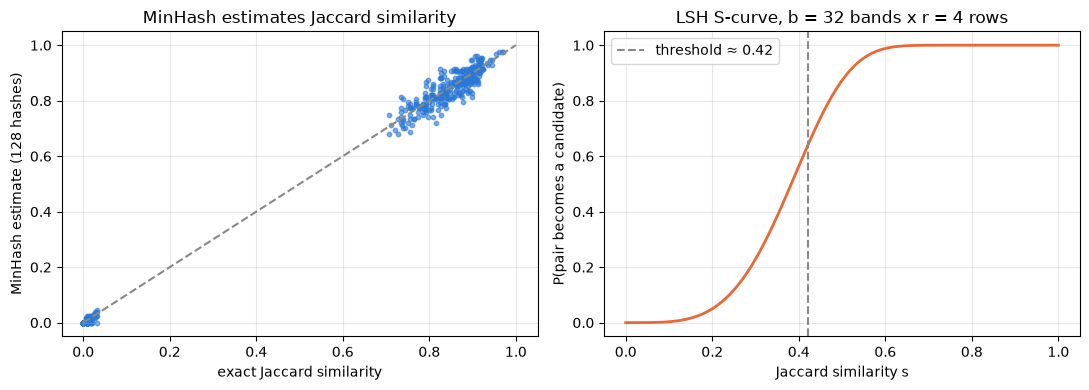

In [12]:
# Ground truth by brute force on a subset: 400 generated (source, near-duplicate) pairs, i.e. about 800 documents.
# Compare ALL pairs inside the subset exactly, then check which of them LSH found.
index_of = {t: i for i, t in enumerate(uniq)}
sub_ids = sorted({index_of[normalise(t)] for pair in near_dup_pairs[:400] for t in pair})
SUBSET = len(sub_ids)
sub_set = set(sub_ids)
t0 = time.perf_counter()
true_pairs = {(i, j) for a, i in enumerate(sub_ids) for j in sub_ids[a + 1:] if jaccard(sh_all[i], sh_all[j]) >= THRESH}
t_brute = time.perf_counter() - t0
lsh_sub = {(i, j) for (i, j) in near_pairs if i in sub_set and j in sub_set}
recall = len(lsh_sub & true_pairs) / max(len(true_pairs), 1)
precision = len(lsh_sub & true_pairs) / max(len(lsh_sub), 1)
n_pairs_sub = SUBSET * (SUBSET - 1) // 2
print(f"subset of {SUBSET:,} docs: brute force checked {n_pairs_sub:,} pairs in {t_brute:.1f} s, found {len(true_pairs)} near-duplicate pairs")
print(f"LSH on the same subset: recall = {recall:.3f}, precision = {precision:.3f}")
assert recall >= 0.9 and precision == 1.0                     # precision is 1 because candidates are verified exactly
est_brute_all = t_brute * (len(uniq) * (len(uniq) - 1) / 2) / n_pairs_sub
print(f"brute force on all {len(uniq):,} docs would take about {est_brute_all / 60:.0f} minutes; MinHash+LSH took {t_lsh:.1f} s")
record("3b. near-duplicate search", "all pairs (estimated)", est_brute_all * 1000, "MinHash + LSH", t_lsh * 1000)

# Accuracy of the MinHash estimate, and the LSH S-curve
pairs_plot = sorted(true_pairs)[:300] + [tuple(rng.choice(sub_ids, size=2, replace=False).tolist()) for _ in range(300)]
true_j = [jaccard(sh_all[i], sh_all[j]) for i, j in pairs_plot]
est_j = [float(np.mean(sigs[i] == sigs[j])) for i, j in pairs_plot]
s = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(true_j, est_j, s=10, alpha=0.6, color=COLORS["blue"])
axes[0].plot([0, 1], [0, 1], ls="--", color=COLORS["grey"])
axes[0].set_xlabel("exact Jaccard similarity"); axes[0].set_ylabel("MinHash estimate (128 hashes)")
axes[0].set_title("MinHash estimates Jaccard similarity")
axes[1].plot(s, 1 - (1 - s ** ROWS) ** BANDS, lw=2, color=COLORS["orange"])
axes[1].axvline((1 / BANDS) ** (1 / ROWS), ls="--", color=COLORS["grey"], label=f"threshold ≈ {(1 / BANDS) ** (1 / ROWS):.2f}")
axes[1].set_xlabel("Jaccard similarity s"); axes[1].set_ylabel("P(pair becomes a candidate)")
axes[1].set_title(f"LSH S-curve, b = {BANDS} bands x r = {ROWS} rows"); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**What just happened?** Hashing removed every exact copy in a fraction of a second, while the list-based method is quadratic (its estimated time for the full corpus is printed above). MinHash + LSH then found the near-duplicate pairs in seconds instead of the many minutes an all-pairs comparison would need, with high recall against brute-force ground truth and perfect precision (because every candidate is verified). The left plot shows the MinHash estimate tracking the true Jaccard similarity; the right plot shows why pairs above 0.7 are essentially always caught while dissimilar pairs (most random documents have $J$ close to 0) almost never become candidates.

To turn near-duplicate **pairs** into **clusters** (keep one document per cluster), merge the pairs with a **disjoint-set union** (notebook 11, section 5).

#### Production notes
- Large LLM pre-training pipelines (for example the data pipelines described for GPT-3, RefinedWeb and FineWeb) use fuzzy document-level deduplication with MinHash-LSH, often combined with exact hashing or exact-substring matching; tools such as `datasketch` and `text-dedup` implement it.
- Deduplicate **before** splitting into train/validation/test, or near-copies leak across the split and inflate evaluation scores ([`08_LLM/08_evaluation`](../../08_LLM/08_evaluation/01_llm_evaluation.ipynb)).
- Tune $b$ and $r$ to place the S-curve's threshold where you want it; more bands with fewer rows = higher recall and more candidates to verify.

### 3.3 A Bloom filter for "have we crawled this URL?"

#### Scenario
The product-page crawler must skip URLs it has already fetched. After a few weeks it has seen hundreds of millions of URLs; a hash **set** of strings needs tens of gigabytes.

**Bloom filter** — a bit array of $m$ bits and $k$ hash functions. `add(x)` sets the $k$ bits $h_1(x)..h_k(x)$; `might_contain(x)` answers *"definitely not seen"* if any of those bits is 0, otherwise *"probably seen"*. There are **no false negatives**, and a tunable rate of **false positives**:

$$m = -\frac{n \ln p}{(\ln 2)^2}, \qquad k = \frac{m}{n}\ln 2, \qquad p \approx \left(1 - e^{-kn/m}\right)^k$$

For $n = 100{,}000$ URLs and $p = 1\%$: $m \approx 958{,}506$ bits ≈ **117 KB** and $k = 7$. We derive the $k$ positions from one hash with **double hashing** $h_i = h_a + i\cdot h_b \bmod m$ (Kirsch and Mitzenmacher, 2006).

In [13]:
class BloomFilter:
    def __init__(self, n_items, fp_rate):
        self.m = math.ceil(-n_items * math.log(fp_rate) / math.log(2) ** 2)    # number of bits
        self.k = max(1, round(self.m / n_items * math.log(2)))                  # number of hash functions
        self.bits = bytearray((self.m + 7) // 8)                                # m bits packed into bytes

    def _positions(self, item):
        d = hashlib.blake2b(item.encode(), digest_size=16).digest()
        ha, hb = int.from_bytes(d[:8], "little"), int.from_bytes(d[8:], "little") | 1
        return [(ha + i * hb) % self.m for i in range(self.k)]                  # double hashing

    def add(self, item):
        for pos in self._positions(item):
            self.bits[pos >> 3] |= 1 << (pos & 7)                               # set bit pos

    def might_contain(self, item):
        return all(self.bits[pos >> 3] & (1 << (pos & 7)) for pos in self._positions(item))


def make_url(i):
    cat = NOUN[i % len(NOUN)].replace(" ", "-")
    return f"https://shopnova.example/{cat}/item-{i}?ref=crawl"

N_URLS = 100_000
seen_urls = [make_url(i) for i in range(N_URLS)]
new_urls = [make_url(i) for i in range(N_URLS, 2 * N_URLS)]

def build_bloom():
    bf = BloomFilter(N_URLS, 0.01)
    for u in seen_urls:
        bf.add(u)
    return bf

def build_set():
    return set(seen_urls)

set_mem, url_set = peak_memory_mb(build_set)
strings_mb = sum(sys.getsizeof(u) for u in seen_urls) / 2**20             # the URL strings themselves
bloom_mem, bloom = peak_memory_mb(build_bloom)
false_neg = sum(not bloom.might_contain(u) for u in seen_urls)
false_pos = sum(bloom.might_contain(u) for u in new_urls)
theory = (1 - math.exp(-bloom.k * N_URLS / bloom.m)) ** bloom.k
assert false_neg == 0                                                         # Bloom filters never miss a stored item
assert all(u in url_set for u in seen_urls) and not any(u in url_set for u in new_urls)
bloom_kb = len(bloom.bits) / 1024
print(f"Bloom filter: m = {bloom.m:,} bits ({bloom_kb:.0f} KB), k = {bloom.k}")
print(f"false negatives: {false_neg}   false positives: {false_pos:,} / {N_URLS:,} = {false_pos / N_URLS:.3%} (theory {theory:.3%})")
print(f"Python set: {set_mem:.1f} MB for the hash table + {strings_mb:.1f} MB for the URL strings it must keep")
record("3c. seen-URL filter memory", "set of URL strings", (set_mem + strings_mb) * 1024, "Bloom filter (1% FP)", bloom_kb, unit="KB")

Bloom filter: m = 958,506 bits (117 KB), k = 7
false negatives: 0   false positives: 1,006 / 100,000 = 1.006% (theory 1.004%)
Python set: 6.0 MB for the hash table + 9.0 MB for the URL strings it must keep


**What just happened?** The Bloom filter used about 117 KB, versus megabytes for the set **plus** the URL strings the set must keep alive. It never forgot a seen URL, and its measured false-positive rate is close to the formula. The price: about 1% of genuinely new URLs are wrongly skipped, which a crawler can accept (it will see popular pages again through other links).

#### Production notes
- Bloom filters sit in front of disk lookups in LSM-tree stores (RocksDB, Cassandra, HBase, LevelDB): "is this key possibly in this file?" saves a disk read for most absent keys.
- Standard Bloom filters cannot delete; use a **counting Bloom filter** or a **cuckoo filter** when items expire.
- Size the filter for the **final** number of items: once $n$ exceeds the design value, the false-positive rate climbs quickly.

---
## 4. Graphs: "people also bought" and PageRank

> **In plain English:** connect products that are bought together, then walk the connections to recommend and to find the most important pages.

### 4.1 Co-purchase recommendations with BFS

#### Scenario
For a product page we need *"customers who bought this also bought..."*. The order history has 60,000 orders over 2,000 products.

#### Naive approach
For each page view, scan every order, find the ones containing the product, and count the other items: $O(\text{orders})$ per request.

#### Better data structure: an adjacency list (a weighted graph)
Build once (offline) the **co-purchase graph**: products are nodes, and the edge weight $w(u, v)$ = number of orders containing both. Stored as a hash map `product -> Counter(neighbour -> weight)`, a request reads one entry: $O(\deg(u))$. For products with few neighbours (new or niche items), a **breadth-first search** to depth 2 adds "friends of friends", scored by $\sum_m w(u, m)\, w(m, v)$.

In [14]:
N_PRODUCTS, N_CATS, N_ORDERS = 2_000, 40, 60_000
product_cat = rng.integers(0, N_CATS, size=N_PRODUCTS)
by_cat = defaultdict(list)
for p_, c_ in enumerate(product_cat):
    by_cat[int(c_)].append(p_)
cat_pop = [1 / np.arange(1, len(by_cat[c]) + 1) for c in range(N_CATS)]       # some products sell more
orders = []
for _ in range(N_ORDERS):
    c = int(rng.integers(N_CATS))
    size = int(rng.integers(2, 6))
    w = cat_pop[c] / cat_pop[c].sum()
    items = set(rng.choice(by_cat[c], size=min(size, len(by_cat[c])), replace=False, p=w).tolist())
    if rng.random() < 0.3:                                                      # cross-category accessory
        items.add(int(rng.integers(N_PRODUCTS)))
    orders.append(sorted(items))
print(f"{len(orders):,} orders, average {np.mean([len(o) for o in orders]):.1f} items per order")

def also_bought_naive(product, k=5):
    counts = Counter()
    for o in orders:                                       # scan ALL orders on every request
        if product in o:
            counts.update(x for x in o if x != product)
    return [x for x, _ in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))[:k]]

def build_graph(orders):
    adj = defaultdict(Counter)
    for o in orders:
        for i in range(len(o)):
            for j in range(i + 1, len(o)):
                adj[o[i]][o[j]] += 1; adj[o[j]][o[i]] += 1
    return adj

t_build, adj = timed(build_graph, orders, repeat=1)

def also_bought(product, k=5):
    return [x for x, _ in sorted(adj[product].items(), key=lambda kv: (-kv[1], kv[0]))[:k]]

def bfs_recommend(product, k=5, max_depth=2):
    # BFS from `product`; depth-1 items first (by weight), then depth-2 items scored by sum of w(u,m) * w(m,v)
    depth = {product: 0}
    frontier, score = deque([product]), Counter()
    while frontier:
        u = frontier.popleft()
        if depth[u] == max_depth:
            continue
        for v, w in adj[u].items():
            if v not in depth:
                depth[v] = depth[u] + 1
                frontier.append(v)
            if depth[v] == 2 and depth[u] == 1:
                score[v] += adj[product][u] * w
    ranked = sorted((v for v in depth if depth[v] == 1), key=lambda v: (-adj[product][v], v))
    ranked += sorted((v for v in depth if depth[v] == 2), key=lambda v: (-score[v], v))
    return ranked[:k], depth

test_products = rng.choice(N_PRODUCTS, size=100, replace=False).tolist()
for p_ in test_products[:30]:
    assert also_bought(p_) == also_bought_naive(p_)
t_naive, _ = timed(lambda: [also_bought_naive(p_) for p_ in test_products[:30]], repeat=1)
t_graph, _ = timed(lambda: [also_bought(p_) for p_ in test_products], repeat=3)
per_naive, per_graph = t_naive / 30 * 1000, t_graph / 100 * 1000
print(f"graph built once in {t_build:.2f} s: {len(adj):,} nodes, {sum(len(v) for v in adj.values()) // 2:,} edges")
print(f"per request: scan orders {per_naive:.2f} ms vs adjacency list {per_graph:.3f} ms")
record("4a. 'also bought' per request", "scan all orders", per_naive, "adjacency list", per_graph)

# BFS depths must match networkx shortest-path lengths (cutoff 2)
G = nx.Graph()
G.add_weighted_edges_from((u, v, w) for u in adj for v, w in adj[u].items() if u < v)
niche = min(adj, key=lambda p_: (len(adj[p_]), p_))                         # the product with the fewest neighbours
recs, depth = bfs_recommend(niche, k=8)
assert depth == nx.single_source_shortest_path_length(G, niche, cutoff=2)
print(f"niche product {niche} has only {len(adj[niche])} direct neighbours; BFS depth-2 recommendations: {recs}")

60,000 orders, average 3.8 items per order


graph built once in 1.14 s: 2,000 nodes, 98,006 edges
per request: scan orders 24.26 ms vs adjacency list 0.101 ms


niche product 1176 has only 37 direct neighbours; BFS depth-2 recommendations: [4, 116, 229, 91, 30, 245, 247, 135]


**Knowledge-graph style explanations.** The same BFS answers *"why was this recommended?"*: the shortest path from the user to the item in a graph of users, products and categories is a human-readable reason.

In [15]:
kg = nx.Graph()
kg.add_edge("user:alice", "product:wireless headphones", relation="bought")
kg.add_edge("product:wireless headphones", "brand:SonicaX", relation="made by")
kg.add_edge("brand:SonicaX", "product:bluetooth speaker", relation="made by")
kg.add_edge("product:wireless headphones", "category:audio", relation="in category")
kg.add_edge("category:audio", "product:power bank", relation="often bought with")
kg.add_edge("user:alice", "product:yoga mat", relation="bought")

def bfs_path(graph, start, goal):
    parent, q = {start: None}, deque([start])
    while q:
        u = q.popleft()
        if u == goal:
            break
        for v in graph.neighbors(u):
            if v not in parent:
                parent[v] = u; q.append(v)
    path, node = [], goal
    while node is not None:
        path.append(node); node = parent[node]
    return path[::-1]

path = bfs_path(kg, "user:alice", "product:bluetooth speaker")
assert len(path) == nx.shortest_path_length(kg, "user:alice", "product:bluetooth speaker") + 1
print(" -> ".join(f"{a} [{kg.edges[a, b_]['relation']}]" for a, b_ in zip(path, path[1:])) + " -> " + path[-1])

user:alice [bought] -> product:wireless headphones [made by] -> brand:SonicaX [made by] -> product:bluetooth speaker


### 4.2 PageRank by power iteration

#### Scenario
Rank the 2,000 product pages by how "central" they are in the **related-products** link graph (each page links to its 5 strongest co-purchase neighbours). Central pages are good candidates for the home page and for crawl priority.

**PageRank** (Brin and Page, 1998) — the long-run probability that a **random surfer** is on a page, if at each step they follow a random outgoing link with probability $\alpha = 0.85$ and jump to a random page otherwise:

$$r_{t+1}(v) = \frac{1-\alpha}{N} + \alpha\left(\sum_{u \to v} \frac{r_t(u)}{\text{outdeg}(u)} + \sum_{u \text{ dangling}} \frac{r_t(u)}{N}\right)$$

(*dangling* pages have no outgoing links; their probability is spread over all pages). **Power iteration** repeats this update until the change is tiny.

#### Naive approach vs. better
The textbook form builds the dense $N\times N$ "Google matrix": $O(N^2)$ memory and $O(N^2)$ work per iteration. The production form keeps only the **edge list** and does a sparse update with `np.bincount`: $O(N + E)$ per iteration.

converged in 117 iterations; max |ours - networkx| = 7.1e-11
dense : 1614 ms, peak 31 MB   |   sparse: 20.1 ms, peak 0.32 MB
top-5 pages: [97, 72, 126, 151, 30] PageRank: [0.00508, 0.00508, 0.00506, 0.00494, 0.00484]


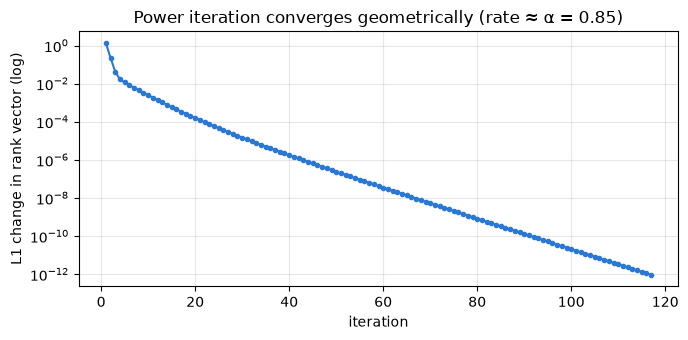

In [16]:
links = {u: [v for v, _ in sorted(adj[u].items(), key=lambda kv: (-kv[1], kv[0]))[:5]] for u in range(N_PRODUCTS)}
for u in rng.choice(N_PRODUCTS, size=20, replace=False).tolist():     # a few pages with no outgoing links (dangling)
    links[int(u)] = []
src = np.array([u for u in links for v in links[u]])
dst = np.array([v for u in links for v in links[u]])
outdeg = np.bincount(src, minlength=N_PRODUCTS)
dangling = outdeg == 0
ALPHA, TOL = 0.85, 1e-12

def pagerank_sparse(n=N_PRODUCTS, alpha=ALPHA, tol=TOL, max_iter=200):
    r = np.full(n, 1 / n)
    history = []
    for _ in range(max_iter):
        spread = np.bincount(dst, weights=r[src] / outdeg[src], minlength=n)   # follow links: O(E)
        new = (1 - alpha) / n + alpha * (spread + r[dangling].sum() / n)
        history.append(np.abs(new - r).sum())
        r = new
        if history[-1] < tol:
            break
    return r, history

def pagerank_dense(n=N_PRODUCTS, alpha=ALPHA, tol=TOL, max_iter=200):
    M = np.zeros((n, n))                                     # dense column-stochastic matrix: n*n floats
    M[dst, src] = 1 / outdeg[src]
    M[:, dangling] = 1 / n
    r = np.full(n, 1 / n)
    for _ in range(max_iter):
        new = (1 - alpha) / n + alpha * (M @ r)
        if np.abs(new - r).sum() < tol:
            return new
        r = new
    return r

t_sparse, (pr, hist) = timed(pagerank_sparse, repeat=3)
t_dense, pr_dense = timed(pagerank_dense, repeat=1)
mem_dense, _ = peak_memory_mb(pagerank_dense)
mem_sparse, _ = peak_memory_mb(pagerank_sparse)

DG = nx.DiGraph()
DG.add_nodes_from(range(N_PRODUCTS))
DG.add_edges_from(zip(src.tolist(), dst.tolist()))
try:
    pr_nx = nx.pagerank(DG, alpha=ALPHA, tol=1e-13)          # uses SciPy if installed
except ImportError:
    from networkx.algorithms.link_analysis.pagerank_alg import _pagerank_python
    pr_nx = _pagerank_python(DG, alpha=ALPHA, tol=1e-13)     # pure-Python fallback
pr_nx = np.array([pr_nx[i] for i in range(N_PRODUCTS)])
assert np.isclose(pr.sum(), 1) and np.abs(pr - pr_nx).max() < 1e-9 and np.abs(pr - pr_dense).max() < 1e-9
print(f"converged in {len(hist)} iterations; max |ours - networkx| = {np.abs(pr - pr_nx).max():.1e}")
print(f"dense : {t_dense * 1000:.0f} ms, peak {mem_dense:.0f} MB   |   sparse: {t_sparse * 1000:.1f} ms, peak {mem_sparse:.2f} MB")
top5 = np.argsort(-pr)[:5]
print("top-5 pages:", top5.tolist(), "PageRank:", np.round(pr[top5], 5).tolist())
record("4b. PageRank, 2k pages (memory)", "dense N x N matrix", mem_dense, "edge list + bincount", mem_sparse, unit="MB")
record("4b. PageRank, 2k pages (time)", "dense N x N matrix", t_dense * 1000, "edge list + bincount", t_sparse * 1000)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(range(1, len(hist) + 1), hist, marker="o", ms=3, color=COLORS["blue"])
ax.set_xlabel("iteration"); ax.set_ylabel("L1 change in rank vector (log)")
ax.set_title("Power iteration converges geometrically (rate ≈ α = 0.85)"); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

**What just happened?** Our sparse power iteration matches `networkx.pagerank` to within $10^{-9}$. The dense version needs memory proportional to $N^2$ (it would need about 8 TB for one million pages), while the edge-list version needs memory proportional to the number of links. The error shrinks by about a factor $\alpha$ per iteration, so the number of iterations depends on the tolerance, not on the graph size.

#### Production notes
- Graph algorithms at scale run on sparse matrices or graph engines (Spark GraphX, graph databases; see [`13_Databases/07_graph_databases`](../../13_Databases/07_graph_databases/01_graph_databases.ipynb) and [`08_LLM/09_knowledge_graphs`](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb)).
- **Personalised PageRank** (restart at the user's own items instead of a random page) is a strong baseline recommender and is used in graph-based retrieval for RAG; see also [`03_Machine_Learning/09_recommendation_systems`](../../03_Machine_Learning/09_recommendation_systems/01_recommendation_systems.ipynb).
- Precompute "also bought" lists offline and store them in a key-value store; serve with a cache.

---
## 5. Dynamic programming: fuzzy matching and Viterbi

> **In plain English:** solve a big problem by filling a table of small sub-answers, so nothing is computed twice.

### 5.1 Edit distance for fuzzy product-name matching

#### Scenario
Users type `wireles headphnes`; the catalogue says `wireless headphones`. Exact lookup fails, so we want catalogue names within a small **edit distance**.

**Levenshtein (edit) distance** — the minimum number of single-character insertions, deletions and substitutions turning string $a$ into string $b$. Dynamic programming: $D[i][j]$ = distance between the first $i$ characters of $a$ and the first $j$ of $b$:

$$D[i][j] = \min\big(D[i-1][j] + 1,\; D[i][j-1] + 1,\; D[i-1][j-1] + [a_i \ne b_j]\big)$$

with $D[i][0] = i$ and $D[0][j] = j$. Time $O(|a|\cdot|b|)$, and memory $O(\min(|a|, |b|))$ if we keep only two rows. The plain recursion without a table recomputes the same sub-problems exponentially often.

In [17]:
calls = 0
def edit_recursive(a, b):
    global calls
    calls += 1
    if not a: return len(b)
    if not b: return len(a)
    return min(edit_recursive(a[1:], b) + 1,                  # delete a[0]
               edit_recursive(a, b[1:]) + 1,                  # insert b[0]
               edit_recursive(a[1:], b[1:]) + (a[0] != b[0])) # substitute (or keep if equal)

def edit_distance(a, b):
    if len(a) < len(b):
        a, b = b, a                                           # keep the shorter string as the row
    prev = list(range(len(b) + 1))                            # D[0][j] = j
    for i, ca in enumerate(a, 1):
        cur = [i] + [0] * len(b)                              # D[i][0] = i
        for j, cb in enumerate(b, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb))
        prev = cur
    return prev[-1]

def edit_table(a, b):
    D = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1): D[i][0] = i
    for j in range(len(b) + 1): D[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i][j] = min(D[i - 1][j] + 1, D[i][j - 1] + 1, D[i - 1][j - 1] + (a[i - 1] != b[j - 1]))
    return D

calls = 0
d_rec = edit_recursive("kitten", "sitting")
print(f"kitten -> sitting: DP = {edit_distance('kitten', 'sitting')}, recursion = {d_rec} using {calls:,} calls "
      f"(the DP table has only {7 * 8} cells)")
print(pd.DataFrame(edit_table("kitten", "sitting"), index=["ε"] + list("kitten"), columns=["ε"] + list("sitting")))
for _ in range(300):
    a = "".join(random.choice("abc") for _ in range(random.randint(0, 6)))
    b_ = "".join(random.choice("abc") for _ in range(random.randint(0, 6)))
    assert edit_distance(a, b_) == edit_recursive(a, b_) == edit_table(a, b_)[-1][-1]

kitten -> sitting: DP = 3, recursion = 3 using 29,737 calls (the DP table has only 56 cells)
   ε  s  i  t  t  i  n  g
ε  0  1  2  3  4  5  6  7
k  1  1  2  3  4  5  6  7
i  2  2  1  2  3  4  5  6
t  3  3  2  1  2  3  4  5
t  4  4  3  2  1  2  3  4
e  5  5  4  3  2  2  3  4
n  6  6  5  4  3  3  2  3


For fuzzy search we only care whether the distance is **at most** $k$ (say 2). Two cheap tricks give a big speed-up without changing the answer:

1. **Length filter:** if $\big||a| - |b|\big| > k$ the distance is surely $> k$.
2. **Banded DP with early exit** (Ukkonen, 1985): only cells with $|i - j| \le k$ can hold values $\le k$, and if a whole row exceeds $k$ we can stop.

In [18]:
def within_k(a, b, k):
    # Edit distance if it is <= k, else None. Banded DP: O(k * len) instead of O(len^2)
    if abs(len(a) - len(b)) > k:
        return None                                           # length filter
    INF = k + 1
    prev = [j if j <= k else INF for j in range(len(b) + 1)]
    for i in range(1, len(a) + 1):
        lo, hi = max(1, i - k), min(len(b), i + k)
        cur = [INF] * (len(b) + 1)
        cur[0] = i if i <= k else INF
        for j in range(lo, hi + 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (a[i - 1] != b[j - 1]), INF)
        if min(cur[max(0, lo - 1):hi + 1]) > k:
            return None                                       # early exit: no cell in the band is <= k
        prev = cur
    return prev[-1] if prev[-1] <= k else None

catalogue = sorted({f"{a} {n}" for a in ADJ for n in NOUN})
def typo(s):
    s, op, i = list(s), int(rng.integers(3)), int(rng.integers(len(s)))
    if op == 0: del s[i]                                      # deletion
    elif op == 1: s.insert(i, chr(97 + int(rng.integers(26))))   # insertion
    else: s[i] = chr(97 + int(rng.integers(26)))              # substitution
    return "".join(s)
user_queries = [typo(typo(catalogue[int(rng.integers(len(catalogue)))])) for _ in range(200)]

def fuzzy_naive(q, k=2):
    return sorted((d, name) for name in catalogue if (d := edit_distance(q, name)) <= k)

def fuzzy_fast(q, k=2):
    return sorted((d, name) for name in catalogue if (d := within_k(q, name, k)) is not None)

for q in user_queries[:20]:
    assert fuzzy_naive(q) == fuzzy_fast(q)
for _ in range(2000):                                         # within_k agrees with the full DP on random strings
    a = "".join(random.choice("ab") for _ in range(random.randint(0, 8)))
    b_ = "".join(random.choice("ab") for _ in range(random.randint(0, 8)))
    for k in (0, 1, 2, 3):
        full = edit_distance(a, b_)
        assert within_k(a, b_, k) == (full if full <= k else None)

t_naive, _ = timed(lambda: [fuzzy_naive(q) for q in user_queries[:20]], repeat=1)
t_fast, results = timed(lambda: [fuzzy_fast(q) for q in user_queries], repeat=1)
found = sum(bool(r) for r in results)
print(f"catalogue: {len(catalogue)} names; example: {user_queries[0]!r} -> {fuzzy_fast(user_queries[0])}")
print(f"per query: full DP {t_naive / 20 * 1000:.1f} ms vs banded + early exit {t_fast / 200 * 1000:.2f} ms; "
      f"{found}/200 typo queries matched within distance 2")
record("5a. fuzzy match vs 500 names", "full DP per name", t_naive / 20 * 1000, "length filter + banded DP", t_fast / 200 * 1000)

catalogue: 500 names; example: 'bluetooh runninglshoes' -> [(2, 'bluetooth running shoes')]
per query: full DP 300.3 ms vs banded + early exit 14.17 ms; 200/200 typo queries matched within distance 2


**What just happened?** The recursion needed tens of thousands of calls for a 6×7 problem that the table solves with 56 cells. For fuzzy search, the length filter and the band skip most of the work, and the early exit abandons hopeless names after a few rows; the answers are identical to the full DP. Every typo query (two random character edits) found its intended name, because two edits can never be more than distance 2 away; some queries also match other close names, so real systems rank the matches by distance and popularity together.

#### Production notes
- Use a compiled library such as `rapidfuzz` for speed; databases offer trigram indexes (PostgreSQL `pg_trgm`) and search engines offer fuzzy queries built on **Levenshtein automata** (Lucene).
- **Damerau-Levenshtein** also counts swapped adjacent letters (`teh` → `the`) as one edit; keyboard-aware costs improve typo correction further.
- Normalise before comparing: lowercase, strip accents, unify units (`50ml` vs `50 ml`).

### 5.2 Viterbi: the most likely tag sequence in a hidden Markov model

#### Scenario
The assistant's lightweight query parser tags each word as **DET** (determiner), **ADJ**, **NOUN** or **VERB** to find the product noun. Some words are ambiguous: *charge* and *case* can be nouns or verbs.

A **hidden Markov model (HMM)** has hidden states (tags) with **start** probabilities $\pi$, **transition** probabilities $P(\text{tag}_t \mid \text{tag}_{t-1})$ and **emission** probabilities $P(\text{word}_t \mid \text{tag}_t)$. We want the tag sequence with the highest joint probability.

- **Brute force:** score all $T^n$ tag sequences ($T$ tags, $n$ words): exponential.
- **Viterbi** (1967): $V_t(s) = \max_{s'} V_{t-1}(s')\, P(s \mid s')\, P(w_t \mid s)$, keeping a back-pointer to the best $s'$. Time $O(n T^2)$. We work with **log-probabilities** so products become sums and nothing underflows.

In [19]:
TAGS = ["DET", "ADJ", "NOUN", "VERB"]
start_p = {"DET": 0.45, "ADJ": 0.15, "NOUN": 0.2, "VERB": 0.2}
trans_p = {
    "DET":  {"DET": 0.01, "ADJ": 0.39, "NOUN": 0.59, "VERB": 0.01},
    "ADJ":  {"DET": 0.01, "ADJ": 0.2,  "NOUN": 0.74, "VERB": 0.05},
    "NOUN": {"DET": 0.1,  "ADJ": 0.05, "NOUN": 0.35, "VERB": 0.5},
    "VERB": {"DET": 0.5,  "ADJ": 0.2,  "NOUN": 0.25, "VERB": 0.05},
}
emit_p = {
    "DET":  {"the": 0.6, "a": 0.4},
    "ADJ":  {"wireless": 0.3, "cheap": 0.3, "fast": 0.25, "black": 0.15},
    "NOUN": {"charger": 0.25, "case": 0.2, "phone": 0.25, "charge": 0.1, "battery": 0.2},
    "VERB": {"charge": 0.4, "case": 0.05, "need": 0.3, "buy": 0.25},
}
for table in (trans_p, emit_p):                               # sanity: every distribution sums to 1
    assert all(abs(sum(d.values()) - 1) < 1e-9 for d in table.values())
assert abs(sum(start_p.values()) - 1) < 1e-9
log = lambda p: math.log(p) if p > 0 else -math.inf

def viterbi(words):
    V = [{s: log(start_p[s]) + log(emit_p[s].get(words[0], 0)) for s in TAGS}]
    back = [{}]
    for t in range(1, len(words)):
        V.append({}); back.append({})
        for s in TAGS:
            prev_best = max(TAGS, key=lambda sp: V[t - 1][sp] + log(trans_p[sp][s]))   # best previous tag
            V[t][s] = V[t - 1][prev_best] + log(trans_p[prev_best][s]) + log(emit_p[s].get(words[t], 0))
            back[t][s] = prev_best
    last = max(TAGS, key=lambda s: V[-1][s])
    path = [last]
    for t in range(len(words) - 1, 0, -1):                    # follow back-pointers
        path.append(back[t][path[-1]])
    return path[::-1], V[-1][last], V

def seq_logprob(words, tags):
    lp = log(start_p[tags[0]]) + log(emit_p[tags[0]].get(words[0], 0))
    for t in range(1, len(words)):
        lp += log(trans_p[tags[t - 1]][tags[t]]) + log(emit_p[tags[t]].get(words[t], 0))
    return lp

def brute_force_tags(words):
    from itertools import product
    return max(product(TAGS, repeat=len(words)), key=lambda tags: seq_logprob(words, tags))

for sentence in ["need a fast charger", "charge the phone", "buy a black phone case", "the wireless charger case"]:
    w = sentence.split()
    tags, lp, V = viterbi(w)
    assert tuple(tags) == brute_force_tags(w) and math.isclose(lp, seq_logprob(w, tags))
    print(f"{sentence:<26} -> {' '.join(f'{x}/{t}' for x, t in zip(w, tags))}")

w = "buy a black phone case".split()
_, _, V = viterbi(w)
print("\nViterbi trellis (log-probabilities) for:", " ".join(w))
pd.DataFrame(V, index=w).T.round(2)

need a fast charger        -> need/VERB a/DET fast/ADJ charger/NOUN
charge the phone           -> charge/VERB the/DET phone/NOUN
buy a black phone case     -> buy/VERB a/DET black/ADJ phone/NOUN case/NOUN
the wireless charger case  -> the/DET wireless/ADJ charger/NOUN case/NOUN

Viterbi trellis (log-probabilities) for: buy a black phone case


,buy,a,black,phone,case
DET,-inf,-4.61,-inf,-inf,-inf
ADJ,-inf,-inf,-7.44,-inf,-inf
NOUN,-inf,-inf,-inf,-9.13,-11.79
VERB,-3.0,-inf,-inf,-inf,-12.82


 n words  brute force ms  Viterbi ms  sequences
       2           0.067       0.035         16
       3           0.221       0.049         64
       4           5.334       0.075        256
       5          13.771       0.104       1024
       6          71.584       0.116       4096
       7         390.207       0.134      16384
       8        1602.173       0.162      65536


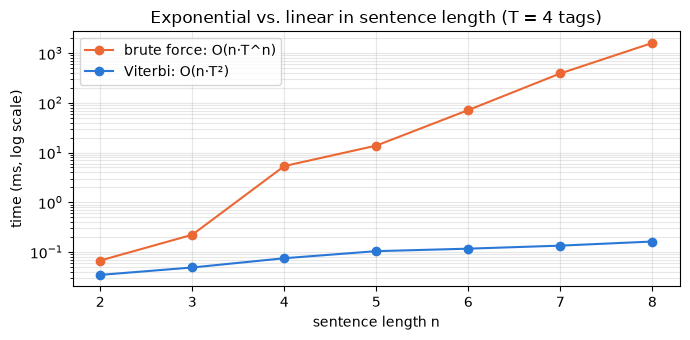

In [20]:
rows = []
words_pool = ["the", "a", "wireless", "cheap", "fast", "charger", "case", "phone", "charge", "need", "buy", "battery"]
for n in range(2, 9):
    w = [words_pool[int(i)] for i in rng.integers(len(words_pool), size=n)]
    t_v, (tags, _, _) = timed(viterbi, w, repeat=3)
    t_b, best = timed(brute_force_tags, w, repeat=1)
    assert math.isclose(seq_logprob(w, tags), seq_logprob(w, best))   # same best score (ties possible in principle)
    rows.append({"n words": n, "brute force ms": t_b * 1000, "Viterbi ms": t_v * 1000, "sequences": len(TAGS) ** n})
vit = pd.DataFrame(rows)
print(vit.round(3).to_string(index=False))
record("5b. HMM tagging, 8 words", "brute force 4^8 sequences", vit.iloc[-1]["brute force ms"], "Viterbi O(nT^2)", vit.iloc[-1]["Viterbi ms"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(vit["n words"], vit["brute force ms"], marker="o", color=COLORS["orange"], label="brute force: O(n·T^n)")
ax.semilogy(vit["n words"], vit["Viterbi ms"], marker="o", color=COLORS["blue"], label="Viterbi: O(n·T²)")
ax.set_xlabel("sentence length n"); ax.set_ylabel("time (ms, log scale)")
ax.set_title("Exponential vs. linear in sentence length (T = 4 tags)"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

**What just happened?** Viterbi tagged the ambiguous *charge* as a **VERB** at the start of "charge the phone" and *case* as a **NOUN** after "phone", exactly like the brute force, which enumerates every tag sequence. On the log-scale plot the brute-force line is a straight line going up (exponential growth, ×4 per extra word) while Viterbi grows linearly.

#### Production notes
- Viterbi decoding is used by **CRF layers** on top of transformers for named-entity recognition ([`07_NLP/04_named_entity_recognition.ipynb`](../../07_NLP/04_named_entity_recognition.ipynb)), in speech-recognition decoders, and in bioinformatics.
- LLM decoding cannot use exact Viterbi (the "state" is the whole prefix), so it uses **beam search**, a pruned cousin that keeps the $k$ best partial sequences in a heap ([`07_NLP/05_language_models_and_generation.ipynb`](../../07_NLP/05_language_models_and_generation.ipynb)).

---
## 6. Caching LLM/API responses: LRU + TTL

> **In plain English:** remember recent answers, forget the least-used ones when full, and throw away answers that are too old.

#### Scenario
The assistant answers many identical questions ("what is your return policy?", "track my order"), and every answer is a paid LLM call that takes over a second. We cache responses keyed by a **normalised request** (model, parameters, prompt).

#### Naive approach
No cache, or an unbounded dict (memory grows forever and answers never refresh when the policy changes).

#### Better data structure: LRU cache with a TTL
- **LRU (least recently used)** eviction keeps at most `capacity` entries and evicts the entry unused for the longest time. A **hash map** (key → node) plus a **doubly linked list** (most recent at the front) make `get` and `put` $O(1)$.
- **TTL (time to live):** each entry expires `ttl` seconds after it was stored, so stale answers are refreshed.

```
head <-> [k3] <-> [k1] <-> [k7] <-> tail       get(k7): unlink k7, insert after head  -> O(1)
 most recent                least recent       put when full: remove node before tail -> O(1)
```

In [21]:
class _Node:
    __slots__ = ("key", "value", "stored_at", "prev", "next")
    def __init__(self, key=None, value=None, stored_at=0.0):
        self.key, self.value, self.stored_at = key, value, stored_at
        self.prev = self.next = None


class LRUTTLCache:
    def __init__(self, capacity, ttl=math.inf, clock=time.monotonic):
        self.capacity, self.ttl, self.clock = capacity, ttl, clock
        self.map = {}                                    # key -> node: O(1) lookup
        self.head, self.tail = _Node(), _Node()          # sentinels: no special cases at the ends
        self.head.next, self.tail.prev = self.tail, self.head
        self.hits = self.misses = self.expired = 0

    def _unlink(self, node):
        node.prev.next, node.next.prev = node.next, node.prev

    def _push_front(self, node):
        node.prev, node.next = self.head, self.head.next
        self.head.next.prev = node
        self.head.next = node

    def get(self, key):
        node = self.map.get(key)
        if node is None:
            self.misses += 1
            return None
        if self.clock() - node.stored_at > self.ttl:     # too old: drop it and report a miss
            self._unlink(node); del self.map[key]
            self.expired += 1; self.misses += 1
            return None
        self._unlink(node); self._push_front(node)       # mark as most recently used
        self.hits += 1
        return node.value

    def put(self, key, value):
        node = self.map.get(key)
        if node is not None:
            node.value, node.stored_at = value, self.clock()
            self._unlink(node); self._push_front(node)
            return
        if len(self.map) >= self.capacity:               # evict the least recently used entry
            lru = self.tail.prev
            self._unlink(lru); del self.map[lru.key]
        node = _Node(key, value, self.clock())
        self.map[key] = node
        self._push_front(node)


class FakeClock:                                         # deterministic time for tests and simulations
    def __init__(self): self.t = 0.0
    def __call__(self): return self.t


class ReferenceCache:
    # Obviously-correct O(n) reference: a list ordered from most to least recently used
    def __init__(self, capacity, ttl, clock):
        self.capacity, self.ttl, self.clock, self.items = capacity, ttl, clock, []
    def get(self, key):
        for i, (k, v, t) in enumerate(self.items):
            if k == key:
                del self.items[i]
                if self.clock() - t > self.ttl:
                    return None
                self.items.insert(0, (k, v, t))
                return v
        return None
    def put(self, key, value):
        self.items = [it for it in self.items if it[0] != key]
        if len(self.items) >= self.capacity:
            self.items.pop()
        self.items.insert(0, (key, value, self.clock()))

for trial in range(50):                                  # random operations: both caches must agree
    clk = FakeClock()
    fast, ref = LRUTTLCache(5, ttl=10, clock=clk), ReferenceCache(5, ttl=10, clock=clk)
    for _ in range(500):
        clk.t += random.random() * 2
        key = random.randint(0, 12)
        if random.random() < 0.5:
            assert fast.get(key) == ref.get(key)
        else:
            v = random.random(); fast.put(key, v); ref.put(key, v)
        assert len(fast.map) <= 5
print("LRU+TTL cache agrees with the reference implementation on 25,000 random operations")

LRU+TTL cache agrees with the reference implementation on 25,000 random operations


 capacity    TTL  hit rate  LLM calls  cost $
       50 10 min     0.468      26593  53.186
       50 60 min     0.469      26555  53.110
       50   none     0.469      26551  53.102
      200 10 min     0.600      20015  40.030
      200 60 min     0.606      19678  39.356
      200   none     0.607      19649  39.298
     1000 10 min     0.678      16101  32.202
     1000 60 min     0.741      12932  25.864
     1000   none     0.747      12657  25.314
     5000 10 min     0.678      16101  32.202
     5000 60 min     0.817       9130  18.260
     5000   none     0.908       4598   9.196



capacity 1000, TTL 60 min: 74.1% of requests served from cache; LLM spend $100 -> $26, waiting time saved ≈ 12.4 user-hours


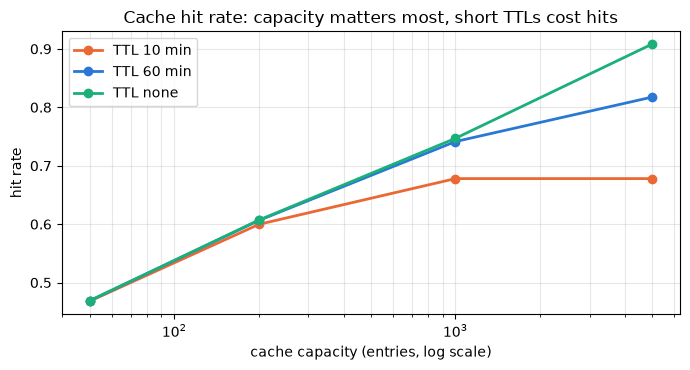

In [22]:
# Simulated traffic: 50,000 requests over 4 hours, 5,000 distinct prompts with Zipf popularity
N_REQ, N_PROMPTS = 50_000, 5_000
COST_PER_CALL, LATENCY_S = 0.002, 1.2                    # ASSUMED dollars and seconds per LLM call (illustrative)
prompt_ids = (rng.zipf(1.2, size=N_REQ) - 1) % N_PROMPTS
arrivals = np.sort(rng.uniform(0, 4 * 3600, size=N_REQ))

def simulate(capacity, ttl):
    clk = FakeClock()
    cache = LRUTTLCache(capacity, ttl=ttl, clock=clk)
    for t, pid in zip(arrivals, prompt_ids):
        clk.t = t
        key = ("assistant-model-v3", 0.0, f"prompt-{pid}")   # model, temperature, normalised prompt
        if cache.get(key) is None:
            cache.put(key, f"answer to prompt {pid}")        # a real system would call the LLM here
    return cache

rows = []
for cap in (50, 200, 1000, 5000):
    for ttl in (600, 3600, math.inf):
        c = simulate(cap, ttl)
        rows.append({"capacity": cap, "TTL": "none" if ttl == math.inf else f"{ttl // 60} min",
                     "hit rate": c.hits / N_REQ, "LLM calls": c.misses, "cost $": c.misses * COST_PER_CALL})
cache_df = pd.DataFrame(rows)
print(cache_df.round(3).to_string(index=False))

# Cross-check with functools.lru_cache (no TTL): same hit count for the same capacity
for cap in (50, 1000):
    @lru_cache(maxsize=cap)
    def call_llm(pid):
        return pid
    for pid in prompt_ids.tolist():
        call_llm(pid)
    assert call_llm.cache_info().hits == simulate(cap, math.inf).hits
best = cache_df[(cache_df.capacity == 1000) & (cache_df.TTL == "60 min")].iloc[0]
print(f"\ncapacity 1000, TTL 60 min: {best['hit rate']:.1%} of requests served from cache; "
      f"LLM spend ${N_REQ * COST_PER_CALL:.0f} -> ${best['cost $']:.0f}, "
      f"waiting time saved ≈ {(N_REQ - best['LLM calls']) * LATENCY_S / 3600:.1f} user-hours")
record("6. LLM calls for 50k requests", "no cache", N_REQ, "LRU 1000 + TTL 60 min", best["LLM calls"], unit="calls")

fig, ax = plt.subplots(figsize=(7, 3.8))
for ttl, c in zip(["10 min", "60 min", "none"], [COLORS["orange"], COLORS["blue"], COLORS["green"]]):
    d = cache_df[cache_df.TTL == ttl]
    ax.semilogx(d.capacity, d["hit rate"], marker="o", lw=2, color=c, label=f"TTL {ttl}")
ax.set_xlabel("cache capacity (entries, log scale)"); ax.set_ylabel("hit rate")
ax.set_title("Cache hit rate: capacity matters most, short TTLs cost hits")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

**What just happened?** Because popularity is highly skewed (a Zipf distribution), even a small cache answers a large share of requests, and the hit rate climbs with capacity. A short TTL lowers the hit rate (entries expire before they are reused) but guarantees freshness; it is a business decision, not a technical one. Our hit counts equal those of Python's `functools.lru_cache` for the same capacity, a good correctness check.

#### Production notes
- The **cache key** must contain everything that changes the answer: model name and version, temperature and other parameters, the system prompt, tool definitions, and the user's language. Cache only **deterministic** calls (temperature 0) or accept that users see the same sample.
- Never share cached personalised answers across users (privacy). Invalidate on policy or price changes (or keep the TTL short for those intents).
- Redis is the usual shared cache: `SET key value EX 3600` gives the TTL and `maxmemory-policy allkeys-lru` gives (approximate, sampled) LRU eviction.
- **Semantic caching** (reuse an answer when a new prompt's embedding is very similar) raises the hit rate but can return a wrong answer for a subtly different question; it needs a strict similarity threshold and evaluation. Provider-side **prompt caching** (reusing the KV cache of a shared prompt prefix) is a different, complementary technique ([`08_LLM/13_inference_optimization.ipynb`](../../08_LLM/13_inference_optimization.ipynb)).

---
## 7. Sliding windows: rate limiting and monitoring

> **In plain English:** look only at the last minute (or last 500 requests), adding new events on one end and dropping old ones from the other.

### 7.1 Sliding-window rate limiter

#### Scenario
The public API allows each client **at most 100 requests in any 60-second window**. One client starts a scraping burst.

#### Naive approach
Store every timestamp of every client in a list and, on each request, count how many fall in the last 60 seconds: $O(\text{history})$ per request, and memory grows forever.

#### Better data structure: a deque per client (sliding-window log)
Timestamps arrive in increasing order, so old ones leave from the **left** and new ones join on the **right**: a **deque** gives $O(1)$ amortised work per request (each timestamp is appended once and popped once) and memory of at most 100 timestamps per client.

> ⚠️ **Common mistake:** a **fixed-window** counter (reset at every full minute) is cheap but lets a client send 100 requests at 12:00:59 and 100 more at 12:01:00, i.e. 200 within two seconds. The sliding window does not have this problem (shown below).

In [23]:
LIMIT, WINDOW = 100, 60.0

class SlidingWindowLimiter:
    def __init__(self, limit=LIMIT, window=WINDOW):
        self.limit, self.window = limit, window
        self.log = defaultdict(deque)                       # client -> timestamps of ALLOWED requests

    def allow(self, client, now):
        q = self.log[client]
        while q and q[0] <= now - self.window:             # drop timestamps that left the window
            q.popleft()
        if len(q) < self.limit:
            q.append(now)
            return True
        return False

class NaiveLimiter:
    def __init__(self, limit=LIMIT, window=WINDOW):
        self.limit, self.window, self.history = limit, window, defaultdict(list)

    def allow(self, client, now):
        recent = sum(1 for t in self.history[client] if t > now - self.window)   # scans the whole history
        if recent < self.limit:
            self.history[client].append(now)
            return True
        return False

class FixedWindowLimiter:
    def __init__(self, limit=LIMIT, window=WINDOW):
        self.limit, self.window, self.counts = limit, window, Counter()

    def allow(self, client, now):
        key = (client, int(now // self.window))             # which minute are we in?
        if self.counts[key] < self.limit:
            self.counts[key] += 1
            return True
        return False

# Traffic: 50 normal clients (~0.5 req/s) for 10 minutes, plus one scraper sending 20 req/s from t = 120 s
events = [(float(t), f"client-{c}") for c in range(50) for t in np.cumsum(rng.exponential(2.0, size=300)) if t < 600]
events += [(120 + i / 20, "scraper") for i in range(20 * 300)]
events.sort()
print(f"{len(events):,} requests")

fast_lim, naive_lim = SlidingWindowLimiter(), NaiveLimiter()
t_fast, dec_fast = timed(lambda: [fast_lim.allow(c, t) for t, c in events], repeat=1)
t_naive, dec_naive = timed(lambda: [naive_lim.allow(c, t) for t, c in events], repeat=1)
assert dec_fast == dec_naive                                # identical allow/deny decisions
blocked = Counter(c for (t, c), ok in zip(events, dec_fast) if not ok)
print(f"naive {t_naive * 1000:.0f} ms vs deque {t_fast * 1000:.0f} ms for all requests; blocked: {dict(blocked)}")
record("7a. rate limiter, all requests", "scan full history", t_naive * 1000, "deque sliding window", t_fast * 1000)

# The fixed-window boundary burst
burst = [(59.0 + i * 0.005, "x") for i in range(100)] + [(60.0 + i * 0.005, "x") for i in range(100)]
fixed_ok = sum(FixedWindowLimiter().allow(c, t) for t, c in burst)
sliding = SlidingWindowLimiter()
sliding_ok = sum(sliding.allow(c, t) for t, c in burst)
print(f"200 requests within ~1.5 s around a minute boundary: fixed window allowed {fixed_ok}, sliding window allowed {sliding_ok}")
assert fixed_ok == 200 and sliding_ok == 100

20,648 requests


naive 1461 ms vs deque 42 ms for all requests; blocked: {'scraper': 5500}
200 requests within ~1.5 s around a minute boundary: fixed window allowed 200, sliding window allowed 100


**What just happened?** Both limiters made exactly the same decisions, and only the scraper was blocked, but the naive version re-scans each client's ever-growing history and is many times slower; it would also run out of memory eventually. The fixed-window limiter let 200 requests through in about 1.5 seconds; the sliding window held the line at 100.

### 7.2 Moving-average monitoring of model latency

#### Scenario
Alert when the **average latency of the last 500 requests** exceeds 250 ms. We also track the **maximum** over the window and an **exponential moving average (EMA)**.

- Naive: recompute `mean(last 500)` and `max(last 500)` from scratch for every request: $O(w)$ each.
- Better: a **running sum** with a deque ($O(1)$: add the new value, subtract the value leaving the window), and a **monotonic deque** for the sliding maximum (it keeps candidate maxima in decreasing order; each value enters and leaves once, so $O(1)$ amortised). The EMA $m_t = \beta m_{t-1} + (1 - \beta) x_t$ needs no window at all.

naive 5490 ms vs deque 189 ms for 60,000 requests (window 500)
degradation starts at request 40,000; first moving-average alert at request 49,787


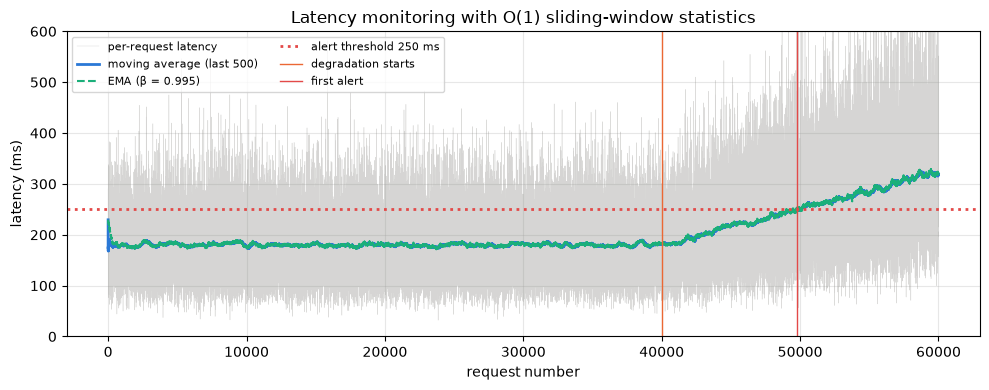

In [24]:
W, ALERT_MS = 500, 250.0
n_req = 60_000
latency = rng.gamma(shape=9.0, scale=20.0, size=n_req)           # healthy: about 180 ms on average
INCIDENT = 40_000
latency[INCIDENT:] *= np.linspace(1.0, 1.8, n_req - INCIDENT)    # a slow degradation starts at request 40,000
latency_list = latency.tolist()

def monitor_naive(xs, w=W):
    means, maxes = [], []
    for i in range(len(xs)):
        window = xs[max(0, i - w + 1):i + 1]                     # rebuild the window every time: O(w)
        means.append(sum(window) / len(window)); maxes.append(max(window))
    return means, maxes

def monitor_fast(xs, w=W):
    window, maxq = deque(), deque()                              # maxq holds indices with decreasing values
    total, means, maxes = 0.0, [], []
    for i, x in enumerate(xs):
        window.append(x); total += x
        if len(window) > w:
            total -= window.popleft()                            # O(1) running sum
        while maxq and xs[maxq[-1]] <= x:
            maxq.pop()                                           # smaller older values can never be the max again
        maxq.append(i)
        if maxq[0] <= i - w:
            maxq.popleft()                                       # the old maximum left the window
        means.append(total / len(window)); maxes.append(xs[maxq[0]])
    return means, maxes

t_naive, (m_naive, x_naive) = timed(monitor_naive, latency_list, repeat=1)
t_fast, (m_fast, x_fast) = timed(monitor_fast, latency_list, repeat=3)
assert np.allclose(m_naive, m_fast) and x_naive == x_fast
ema, beta, ema_vals = latency_list[0], 0.995, []
for x in latency_list:
    ema = beta * ema + (1 - beta) * x; ema_vals.append(ema)
first_alert = next(i for i, m in enumerate(m_fast) if i >= W and m > ALERT_MS)
print(f"naive {t_naive * 1000:.0f} ms vs deque {t_fast * 1000:.0f} ms for {n_req:,} requests (window {W})")
print(f"degradation starts at request {INCIDENT:,}; first moving-average alert at request {first_alert:,}")
record("7b. windowed mean+max, 60k points", "recompute window", t_naive * 1000, "running sum + monotonic deque", t_fast * 1000)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(latency, lw=0.3, alpha=0.35, color=COLORS["grey"], label="per-request latency")
ax.plot(m_fast, lw=2, color=COLORS["blue"], label=f"moving average (last {W})")
ax.plot(ema_vals, lw=1.5, ls="--", color=COLORS["green"], label="EMA (β = 0.995)")
ax.axhline(ALERT_MS, color=COLORS["red"], ls=":", lw=2, label=f"alert threshold {ALERT_MS:.0f} ms")
ax.axvline(INCIDENT, color=COLORS["orange"], lw=1, label="degradation starts")
ax.axvline(first_alert, color=COLORS["red"], lw=1, label="first alert")
ax.set_ylim(0, 600); ax.set_xlabel("request number"); ax.set_ylabel("latency (ms)")
ax.set_title("Latency monitoring with O(1) sliding-window statistics"); ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**What just happened?** The deque versions produce exactly the same moving average (up to floating-point rounding, hence `np.allclose`) and the same moving maximum as the naive recomputation, many times faster. The alert fires well after the degradation starts: the slowdown is gradual, so the average only crosses 250 ms once latency has grown by roughly 40%, and the 500-request window adds some extra lag. A longer window means fewer false alarms but slower detection; production alerts often combine a fast and a slow window.

#### Production notes
- Rate limiting usually lives in an API gateway or in Redis (sorted sets for sliding logs, or the cheaper **token bucket** / sliding-window-counter approximations). Return HTTP **429 Too Many Requests** with a `Retry-After` header.
- Running sums of floats accumulate rounding error over millions of updates; recompute the sum from the window occasionally.
- Monitoring systems (Prometheus, Grafana) compute windowed rates and quantiles; latency **percentiles** (p95, p99) matter more than averages and need sketches such as t-digest or histograms ([`15_MLOps/06_monitoring`](../../15_MLOps/06_monitoring/01_monitoring.ipynb)).

---
## 8. Binary search in ML engineering

> **In plain English:** when a yes/no answer flips only once, test the middle and throw away half of the options every time.

### 8.1 Threshold tuning

#### Scenario
A fraud model outputs a score for each transaction. The business requires **recall ≥ 95%** (catch at least 95% of fraud) and wants the **highest** threshold that achieves it (fewer false alarms). The validation set has 1,000,000 transactions.

**Key fact:** recall(t) = fraction of positives with score ≥ t can only go **down** as $t$ goes up (it is **monotone**), and monotone conditions are what binary search needs.

- Naive: try 1,001 thresholds $0.000, 0.001, \dots, 1$ and compute recall over all 1,000,000 rows for each: $O(T\cdot n)$.
- Binary search over the same grid: about $\log_2 1{,}001 \approx 10$ recall evaluations: $O(n\log T)$.
- Even better: sort the positive scores once and read the answer off with `bisect`: $O(n\log n)$ once, then $O(\log n)$ per question ("what threshold for 90%? 99%?").

In [25]:
n_val = 1_000_000
y_val = rng.random(n_val) < 0.02                                   # 2% fraud
score_val = np.where(y_val, rng.beta(5, 2, n_val), rng.beta(2, 5, n_val))
pos_scores = score_val[y_val]
GRID = np.round(np.linspace(0, 1, 1_001), 3)
TARGET = 0.95
evaluations = 0

def recall_at(t):
    global evaluations
    evaluations += 1
    return float(((score_val >= t) & y_val).sum() / y_val.sum())   # O(n) pass over all rows

def linear_scan():
    best = None
    for t in GRID:                                                 # try every threshold
        if recall_at(t) >= TARGET:
            best = t
    return best

def binary_search_threshold():
    lo, hi = 0, len(GRID) - 1                                      # invariant: recall(GRID[lo]) >= TARGET
    assert recall_at(GRID[lo]) >= TARGET
    while lo < hi:
        mid = (lo + hi + 1) // 2                                   # upper middle, so the loop always shrinks
        if recall_at(GRID[mid]) >= TARGET:
            lo = mid                                               # mid works: the answer is mid or higher
        else:
            hi = mid - 1                                           # mid fails: the answer is below mid
    return GRID[lo]

evaluations = 0; t_lin, th_lin = timed(linear_scan, repeat=1); ev_lin = evaluations
evaluations = 0; t_bin, th_bin = timed(binary_search_threshold, repeat=1); ev_bin = evaluations
assert th_lin == th_bin

sorted_pos = np.sort(pos_scores)
def threshold_for_recall(target):
    # Largest grid threshold t with (#positives >= t) / n_pos >= target, using bisect on the sorted positives
    need = math.ceil(target * len(sorted_pos))                     # at least this many positives must be >= t
    t_max = sorted_pos[len(sorted_pos) - need]                     # the need-th largest positive score
    return GRID[bisect.bisect_right(GRID.tolist(), t_max) - 1]     # largest grid value <= t_max

assert threshold_for_recall(TARGET) == th_bin
precision = float(y_val[score_val >= th_bin].mean())
print(f"threshold = {th_bin}: recall = {recall_at(th_bin):.4f}, precision = {precision:.3f}")
print(f"linear scan: {ev_lin:,} evaluations, {t_lin:.1f} s | binary search: {ev_bin} evaluations, {t_bin * 1000:.0f} ms")
print("thresholds for other recall targets via bisect:", {r: float(threshold_for_recall(r)) for r in (0.8, 0.9, 0.99)})
record("8a. threshold for recall >= 95%", "scan 1,001 thresholds", t_lin * 1000, "binary search", t_bin * 1000)

threshold = 0.415: recall = 0.9503, precision = 0.084
linear scan: 1,001 evaluations, 7.8 s | binary search: 11 evaluations, 77 ms
thresholds for other recall targets via bisect: {0.8: 0.574, 0.9: 0.487, 0.99: 0.292}


### 8.2 Finding the first bad model version (the `git bisect` idea)

#### Scenario
The model registry holds versions 1 to 300 (one per nightly retrain). Version 1 was good; version 300 has lost several accuracy points. Each evaluation runs the full test suite and takes about **25 minutes**. Which version introduced the regression?

If "bad" stays bad once it appears (the property is **monotone** over versions), binary search needs at most $\lceil\log_2 299\rceil = 9$ evaluations instead of up to 299. This is exactly what `git bisect` does over commits:

```
git bisect start
git bisect bad HEAD           # current version is bad
git bisect good v1.0          # this old version was good
git bisect run python evaluate.py   # script exits 0 = good, 1 = bad; git finds the first bad commit
```

first bad version = 217
binary search: 8 evaluations (3.3 h): [150, 225, 187, 206, 215, 220, 217, 216]
linear scan  : 216 evaluations (90.0 h)


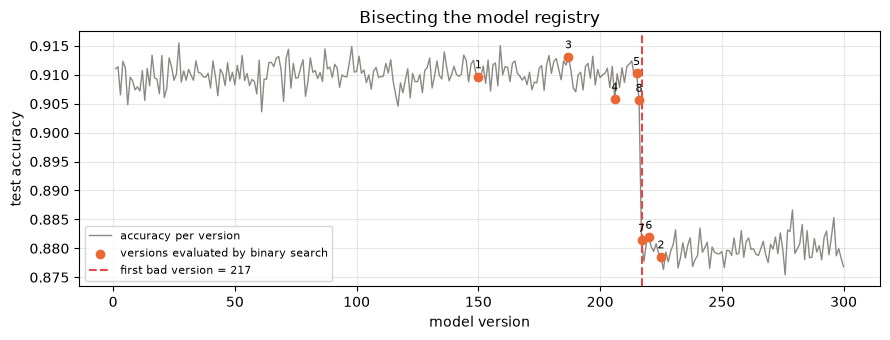

In [26]:
N_VERSIONS, FIRST_BAD, EVAL_MINUTES = 300, 217, 25
version_acc = 0.91 + rng.normal(0, 0.002, size=N_VERSIONS + 1)    # small run-to-run noise
version_acc[FIRST_BAD:] -= 0.03                                   # the regression
probes = []

def is_bad(v, threshold=0.895):
    probes.append(v)                                              # every call = one 25-minute evaluation
    return version_acc[v] < threshold

def first_bad_version(good, bad):
    # Invariant: `good` is known good, `bad` is known bad. Shrink the gap until they are neighbours.
    while bad - good > 1:
        mid = (good + bad) // 2
        if is_bad(mid):
            bad = mid
        else:
            good = mid
    return bad

probes = []
found = first_bad_version(1, N_VERSIONS)
bisect_probes = list(probes)
probes = []
linear = next(v for v in range(2, N_VERSIONS + 1) if is_bad(v))
linear_probes = len(probes)
assert found == linear == FIRST_BAD
print(f"first bad version = {found}")
print(f"binary search: {len(bisect_probes)} evaluations ({len(bisect_probes) * EVAL_MINUTES / 60:.1f} h): {bisect_probes}")
print(f"linear scan  : {linear_probes} evaluations ({linear_probes * EVAL_MINUTES / 60:.1f} h)")
record("8b. find first bad version (300)", "linear scan", linear_probes * EVAL_MINUTES, "binary search", len(bisect_probes) * EVAL_MINUTES, unit="eval-minutes")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(range(1, N_VERSIONS + 1), version_acc[1:], lw=1, color=COLORS["grey"], label="accuracy per version")
ax.scatter(bisect_probes, version_acc[bisect_probes], color=COLORS["orange"], zorder=3, label="versions evaluated by binary search")
for i, v in enumerate(bisect_probes, 1):
    ax.annotate(str(i), (v, version_acc[v]), textcoords="offset points", xytext=(0, 6), fontsize=8, ha="center")
ax.axvline(FIRST_BAD, color=COLORS["red"], ls="--", label=f"first bad version = {FIRST_BAD}")
ax.set_xlabel("model version"); ax.set_ylabel("test accuracy"); ax.set_title("Bisecting the model registry")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**What just happened?** Binary search found version 217 with 8 evaluations (about 3.3 hours of compute) instead of 216 evaluations (90 hours) for a linear scan from the oldest version. The numbered dots show the probes zooming in on the regression.

> ⚠️ **Common mistake:** bisecting a **non-monotone** or **noisy** signal. If the evaluation is flaky (accuracy varies between runs by about as much as the regression), a single wrong answer sends the search into the wrong half. Fix it by making the check robust (fixed seeds, larger test set, majority vote over repeated runs, or a statistical test) before bisecting.

#### Production notes
- Keep every model version **reproducible** (code commit, data snapshot, config, seed) in a registry so you can evaluate any old version ([`15_MLOps/05_model_registry`](../../15_MLOps/05_model_registry/), [`20_Git_and_DevOps`](../../20_Git_and_DevOps/)).
- Binary search also tunes other monotone settings: the largest batch size that fits in GPU memory, the smallest replica count that meets a latency target, the lowest quantisation level that keeps accuracy.

---
## 9. Results summary and the big-O cheat sheet

> **In plain English:** every speed-up measured in this notebook, and which structure to reach for in which situation.

Every row below was **measured in this run** (times differ between machines; the *ratios* are what matter).

In [27]:
summary = pd.DataFrame(RESULTS)
summary["naive value"] = summary["naive value"].map(lambda v: f"{v:,.3g}")
summary["better value"] = summary["better value"].map(lambda v: f"{v:,.3g}")
print(summary.to_string(index=False))

                                case                     naive                        better         unit naive value better value  gain (x)
1. top-10 of 1M scores (pure Python)                  sorted()             heap from scratch           ms    1.69e+03          356       4.7
     1. top-10 of 1M scores (memory)                  sorted()             heap from scratch           KB    5.47e+04         1.46   37427.5
      1. top-10 of 1M scores (NumPy)                np.argsort               np.argpartition           ms         408         13.7      29.7
      2a. autocomplete per keystroke            scan query log           trie + cached top-5           µs    4.03e+03         5.22     771.6
        2b. BPE training, 150 merges         recount all pairs         heap + inverted index           ms     1.2e+04     2.26e+03       5.3
      2c. longest-match tokenisation           scan vocabulary                     trie walk      µs/word         446         7.28      61.3
           3a

### Big-O cheat sheet for AI engineers

| task in an AI system | naive | better structure / algorithm | time (better) | memory (better) |
|---|---|---|---|---|
| top-k of $n$ scores (retrieval, reranking, top-k sampling) | full sort $O(n\log n)$ | size-$k$ heap / `argpartition` | $O(n\log k)$ / $O(n)$ avg | $O(k)$ |
| merge results from $s$ shards | concatenate + sort | heap merge of local top-$k$ | $O(sk\log k)$ | $O(sk)$ |
| prefix autocomplete | scan log $O(NL)$ | trie with cached top-k | $O(L)$ per keystroke | $O(\text{total chars})$ |
| longest-match tokenisation | try every vocab entry $O(\lvert V\rvert)$ per position | trie walk | $O(\text{match length})$ per position | $O(\text{vocab chars})$ |
| BPE training | recount all pairs per merge | pair hash map + inverted index + heap | $O(\text{affected words})$ per merge | $O(\text{corpus})$ |
| exact dedup | pairwise $O(n^2)$ | hash set of digests | $O(n)$ | 16 bytes per doc |
| near-duplicate detection | all pairs $O(n^2)$ | MinHash + LSH | $\approx O(n)$ + candidates | $O(n\cdot\text{num\_perm})$ |
| "seen before?" for billions of keys | hash set of keys | Bloom filter | $O(k)$ | $\approx 9.6$ bits per item at 1% FP |
| related items | scan all orders | adjacency list (+ BFS) | $O(\deg)$ / $O(V+E)$ | $O(V+E)$ |
| node importance | dense matrix $O(N^2)$ | sparse power iteration | $O(E)$ per iteration | $O(N+E)$ |
| fuzzy string match | full DP for every name | length filter + banded DP | $O(k\cdot L)$ per pair | $O(L)$ |
| sequence labelling (HMM/CRF) | enumerate $T^n$ sequences | Viterbi DP | $O(nT^2)$ | $O(nT)$ |
| response cache | unbounded dict / none | hash map + doubly linked list (LRU) + TTL | $O(1)$ | $O(\text{capacity})$ |
| rate limiting, moving stats | rescan history / window | deque, running sum, monotonic deque | $O(1)$ amortised | $O(w)$ |
| threshold / regression search | try all $T$ options | binary search (monotone condition) | $O(\log T)$ evaluations | $O(1)$ |

### Production checklist
- **Measure first.** Profile with real data sizes; the slow part is often not where you expect.
- **Prefer the library** (heapq, NumPy, a vector database, Redis, a tokenizer library) once you understand what it does; write your own only for teaching, for special requirements, or when nothing fits.
- **Verify** every optimisation against the simple version on many random inputs (we used `assert` throughout).
- **Know your trade-off:** approximate structures (LSH, Bloom filters, approximate nearest neighbours, sampled LRU) trade a small, measurable error for large speed or memory gains; document the error rate.

## 🔗 How this connects to the rest of the course

| case study | where it appears in this repo |
|---|---|
| top-k retrieval, re-ranking | [`08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb`](../../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb), [`08_LLM/19_industry_rag_pipeline.ipynb`](../../08_LLM/19_industry_rag_pipeline.ipynb), [`13_Databases/03_vector_db`](../../13_Databases/03_vector_db/01_vector_databases.ipynb) |
| tokenisation, BPE | [`07_NLP/01_text_preprocessing.ipynb`](../../07_NLP/01_text_preprocessing.ipynb), [`08_LLM/00_start_here_how_llms_work.ipynb`](../../08_LLM/00_start_here_how_llms_work.ipynb) |
| dedup, data quality | [`08_LLM/10_synthetic_data`](../../08_LLM/10_synthetic_data/01_synthetic_data.ipynb), [`13_Databases/06_data_engineering`](../../13_Databases/06_data_engineering/01_data_engineering.ipynb) |
| graphs, recommendations | [`03_Machine_Learning/09_recommendation_systems/02_industry_product_recommender.ipynb`](../../03_Machine_Learning/09_recommendation_systems/02_industry_product_recommender.ipynb), [`08_LLM/09_knowledge_graphs`](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb) |
| Viterbi, edit distance | [`07_NLP/04_named_entity_recognition.ipynb`](../../07_NLP/04_named_entity_recognition.ipynb), [`11_Reinforcement_Learning/02_dynamic_programming.ipynb`](../../11_Reinforcement_Learning/02_dynamic_programming.ipynb) |
| caching, rate limiting | [`08_LLM/20_industry_llm_application_patterns.ipynb`](../../08_LLM/20_industry_llm_application_patterns.ipynb), [`12_FastAPI/04_industry_production_ml_api.ipynb`](../../12_FastAPI/04_industry_production_ml_api.ipynb) |
| monitoring, model versions | [`15_MLOps/06_monitoring`](../../15_MLOps/06_monitoring/01_monitoring.ipynb), [`16_Deployment/05_industry_safe_model_rollout_strategies.ipynb`](../../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb) |

## Recap

- **Heaps** turn "sort everything, keep 10" into one pass with $O(k)$ memory, and merge results from shards exactly.
- **Tries** make autocomplete and longest-match tokenisation independent of vocabulary or log size; **BPE** training is hash maps plus a lazily-updated priority queue.
- **Hashing** removes exact duplicates in linear time; **MinHash + LSH** finds near-duplicates without comparing all pairs; **Bloom filters** answer "seen before?" in a few bits per item with no false negatives.
- **Adjacency lists + BFS** serve graph recommendations and explanations; **PageRank** is a sparse power iteration.
- **Dynamic programming** (edit distance, Viterbi) replaces exponential search with polynomial tables; banding and early exit speed up fuzzy matching further.
- An **LRU cache with TTL** (hash map + doubly linked list) cuts LLM cost and latency on skewed traffic.
- **Deques** give $O(1)$ sliding windows for rate limiting and monitoring.
- **Binary search** works on any **monotone** yes/no question: thresholds, first bad version, capacity limits.

## Practice problems

Try each one before opening the solution. Every code solution was run and tested.

**1. (Easy, conceptual)** Your retriever must return the top 20 of 50 million scores. Compare a full sort, a size-20 heap and `np.argpartition` in time and extra memory. When would you still sort everything?

<details><summary>Show solution</summary>

Full sort: $O(n\log n)$ time, $O(n)$ extra memory (an index array of 50M entries ≈ 400 MB as int64). Heap: $O(n\log k)$ time with $\log_2 20 \approx 4.3$, $O(k)$ memory, and it works on a stream or across shards. `argpartition`: $O(n)$ average time, $O(n)$ memory for the index array, very fast in NumPy. Sort everything only when you really need the full ranking (for example to paginate deep into the results or to compute ranking metrics over all items).

</details>

**2. (Easy, coding)** Write `merge_topk(shard_results, k)` that merges each shard's local top-k list of `(score, item_id)` into the global top-k.

<details><summary>Show solution</summary>


The global top-k is always contained in the union of the local top-k lists, so a heap over those few candidates is exact.

```python
def merge_topk(shard_results, k):
    # shard_results: list of lists of (score, item_id); returns the global top-k (score, item_id), best first
    return heapq.nlargest(k, (pair for shard in shard_results for pair in shard))

shards = [[(0.9, "a"), (0.4, "b")], [(0.95, "c"), (0.1, "d")], [(0.5, "e")]]
assert merge_topk(shards, 3) == [(0.95, "c"), (0.9, "a"), (0.5, "e")]
for _ in range(200):
    data = [(random.random(), i) for i in range(random.randint(1, 200))]
    k = random.randint(1, 10)
    parts = [data[i::4] for i in range(4)]
    local = [heapq.nlargest(k, p) for p in parts]          # each shard sends only its local top-k
    assert merge_topk(local, k) == sorted(data, reverse=True)[:k]
```

</details>

**3. (Medium, calculation)** Size a Bloom filter for 10 million URLs with a 0.1% false-positive rate. How many bits, how many MiB, and how many hash functions?

<details><summary>Show solution</summary>


$m = -n\ln p/(\ln 2)^2 \approx 143.8$ million bits $\approx 17.1$ MiB, and $k = (m/n)\ln 2 \approx 10$. A set of 10 million URL strings would need on the order of a gigabyte.

```python
n, p = 10_000_000, 0.001
m = math.ceil(-n * math.log(p) / math.log(2) ** 2)
k = round(m / n * math.log(2))
print(f"m = {m:,} bits = {m / 8 / 2**20:.1f} MiB, k = {k}")
assert 143_000_000 < m < 144_000_000 and k == 10
```

</details>

**4. (Medium, coding)** Return the `k` most frequent words of a token stream (ties alphabetically) using a hash map and a heap.

<details><summary>Show solution</summary>


```python
def top_k_words(stream, k):
    counts = Counter(stream)                               # hash map: word -> count, O(n)
    # heap of size k over (count, word); ties broken alphabetically (smaller word first)
    return [w for c, w in heapq.nsmallest(k, ((-c, w) for w, c in counts.items()))]

text = "the cat and the dog and the bird".split()
assert top_k_words(text, 2) == ["the", "and"]
for _ in range(200):
    words = [random.choice("abcdefg") for _ in range(random.randint(1, 50))]
    k = random.randint(1, 5)
    expected = [w for w, c in sorted(Counter(words).items(), key=lambda wc: (-wc[1], wc[0]))[:k]]
    assert top_k_words(words, k) == expected
```

</details>

**5. (Medium, conceptual)** Why does Viterbi run in $O(nT^2)$, and why can't an LLM use exact Viterbi decoding?

<details><summary>Show solution</summary>

For each of the $n$ positions and each of the $T$ current tags, Viterbi takes a maximum over the $T$ previous tags: $n \cdot T \cdot T$. This works because of the **Markov property**: the best path into tag $s$ at time $t$ only depends on the previous tag, so one number per (position, tag) summarises the whole past. In an LLM the next-token distribution depends on the **entire prefix**, so the "state" is the whole sequence and the number of states grows as $|V|^t$; exact DP is impossible and we fall back to greedy decoding, sampling or **beam search** (keep the best $k$ prefixes).

</details>

**6. (Medium, coding)** Implement a **token-bucket** rate limiter (capacity $C$, refill rate $r$ tokens/s) and check the property "in any time interval of length $\Delta$, at most $C + r\Delta$ requests are allowed".

<details><summary>Show solution</summary>


Refill lazily on each request from the elapsed time; this is $O(1)$ time and memory per client, cheaper than the sliding log but it allows bursts of up to $C$.

```python
class TokenBucket:
    # capacity tokens; refills `rate` tokens per second; each request spends one token
    def __init__(self, capacity, rate):
        self.capacity, self.rate = capacity, rate
        self.tokens, self.last = float(capacity), 0.0

    def allow(self, now):
        self.tokens = min(self.capacity, self.tokens + (now - self.last) * self.rate)   # refill lazily
        self.last = now
        if self.tokens >= 1:
            self.tokens -= 1
            return True
        return False

tb = TokenBucket(capacity=10, rate=2)                    # bursts of 10, then 2 per second on average
times = sorted(random.uniform(0, 100) for _ in range(5000))
allowed = [t for t in times if tb.allow(t)]
# property: in ANY interval [a, b] at most capacity + rate * (b - a) requests are allowed
for i in range(0, len(allowed), 7):
    for j in range(i, min(i + 60, len(allowed))):
        assert j - i + 1 <= 10 + 2 * (allowed[j] - allowed[i]) + 1e-9
assert 180 <= len(allowed) <= 211                         # about 2/s for 100 s, plus the initial burst
```

</details>

**7. (Hard, coding)** Implement an $O(1)$ **LFU** (least-frequently-used) cache, breaking ties by least recent use, and test it against a brute-force reference.

<details><summary>Show solution</summary>


Keep `key -> count` and, for every count, an `OrderedDict` of keys in recency order, plus the current minimum count. Every operation touches a constant number of hash-map entries.

```python
class LFUCache:
    # O(1) LFU: evict the least frequently used key; ties -> least recently used among them
    def __init__(self, capacity):
        self.capacity = capacity
        self.vals, self.freq = {}, {}                     # key -> value, key -> use count
        self.buckets = defaultdict(OrderedDict)           # count -> keys in LRU order (oldest first)
        self.min_freq = 0

    def _touch(self, key):
        f = self.freq[key]
        del self.buckets[f][key]
        if not self.buckets[f]:
            del self.buckets[f]
            if self.min_freq == f:
                self.min_freq = f + 1
        self.freq[key] = f + 1
        self.buckets[f + 1][key] = None

    def get(self, key):
        if key not in self.vals:
            return None
        self._touch(key)
        return self.vals[key]

    def put(self, key, value):
        if self.capacity == 0:
            return
        if key in self.vals:
            self.vals[key] = value
            self._touch(key)
            return
        if len(self.vals) >= self.capacity:
            old, _ = self.buckets[self.min_freq].popitem(last=False)   # least recent among least frequent
            if not self.buckets[self.min_freq]:
                del self.buckets[self.min_freq]
            del self.vals[old], self.freq[old]
        self.vals[key], self.freq[key] = value, 1
        self.buckets[1][key] = None
        self.min_freq = 1

class LFUReference:                                        # O(n) brute force with explicit timestamps
    def __init__(self, capacity):
        self.capacity, self.data, self.clock = capacity, {}, 0
    def get(self, key):
        self.clock += 1
        if key not in self.data:
            return None
        v, f, _ = self.data[key]
        self.data[key] = (v, f + 1, self.clock)
        return v
    def put(self, key, value):
        self.clock += 1
        if self.capacity == 0:
            return
        if key in self.data:
            _, f, _ = self.data[key]
            self.data[key] = (value, f + 1, self.clock)
            return
        if len(self.data) >= self.capacity:
            victim = min(self.data, key=lambda k: (self.data[k][1], self.data[k][2]))
            del self.data[victim]
        self.data[key] = (value, 1, self.clock)

for trial in range(100):
    cap = random.randint(0, 6)
    a, r = LFUCache(cap), LFUReference(cap)
    for _ in range(400):
        key = random.randint(0, 10)
        if random.random() < 0.5:
            assert a.get(key) == r.get(key)
        else:
            v = random.random(); a.put(key, v); r.put(key, v)
```

</details>

**8. (Hard, conceptual)** Your regression check is noisy: each evaluation of a version has a 10% chance of giving the wrong good/bad answer. What can go wrong with binary search, and how would you fix it?

<details><summary>Show solution</summary>

Binary search trusts every answer: one wrong answer at an early probe discards the half that contains the true first bad version, and the search confidently returns a wrong version (with 9 probes the chance that all answers are correct is only $0.9^9 \approx 39\%$). Fixes: reduce noise (fixed seeds, bigger test set); repeat each probe and take a majority vote (with 5 runs the per-probe error drops to about 0.86%); use a statistical test on the accuracy difference; verify the result at the end by re-evaluating versions `found - 1` and `found` several times; or use a noisy binary search that keeps a probability for every version and updates it after each observation (Bayesian bisection).

</details>

## Further reading

- Cormen et al., *Introduction to Algorithms* (CLRS), 4th ed.: ch. 6 (heaps and priority queues), ch. 11 (hash tables), ch. 14 (dynamic programming), ch. 20 (BFS).
- Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets*, ch. 3 (MinHash, LSH), ch. 4 (Bloom filters, streams), ch. 5 (PageRank); free at [mmds.org](http://www.mmds.org/).
- Jurafsky & Martin, *Speech and Language Processing*, 3rd ed. draft (free online): chapters on BPE tokenisation, minimum edit distance, and HMMs/Viterbi.
- Kleppmann, *Designing Data-Intensive Applications*: caches, Bloom filters in LSM-trees, stream processing.
- Sennrich, Haddow & Birch (2016), "Neural Machine Translation of Rare Words with Subword Units" (BPE); Song et al. (2021), "Fast WordPiece Tokenization".

## Next notebook

➡️ You have finished the Data Structures & Algorithms module. Continue with a production AI system that uses many of these ideas together: [`08_LLM/19_industry_rag_pipeline.ipynb`](../../08_LLM/19_industry_rag_pipeline.ipynb), or go back to the previous notebook [`11_advanced_tries_strings_and_range_queries.ipynb`](11_advanced_tries_strings_and_range_queries.ipynb).